# LA LA Stay · Airbnb Los Ángeles
### Análisis de datos — Andrés Arismendi (Uniandes)

**Fuente:** Inside Airbnb, `listings.csv.gz` de Los Ángeles (extracción del 14 al 16 de septiembre de 2026), guardado en `data/raw/`.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', 100)

# Semilla única para todo lo aleatorio del notebook (divisiones, validación cruzada, muestras)
SEED = 42


In [2]:
# Rutas del proyecto: funciona desde cualquier carpeta dentro del repositorio
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'data').is_dir():
            return folder
    return start

ROOT = find_project_root()
RAW_FILE = ROOT / 'data' / 'raw' / 'listings.csv.gz'
print('Archivo:', RAW_FILE)

Archivo: /tmp/Proyecto 2/data/raw/listings.csv.gz


### Cargar los datos
`id` y `host_id` se leen como **texto**: los IDs de Inside Airbnb tienen hasta 19 dígitos y, si se leen como número o pasan por Excel, pierden los últimos dígitos.

In [3]:
df = pd.read_csv(RAW_FILE, compression='gzip', low_memory=False,
                 dtype={'id': str, 'host_id': str})

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
df.head()

Filas: 43,781 | Columnas: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,20260914002257,2026-09-15,NaN,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3008,https://www.airbnb.com/users/show/3008,1462506333679450606,https://www.airbnb.com/users/profile/146250633...,⁨Chas.⁩,NaN,17,11,15,7,"Los Angeles, CA",Professional and technical writer.\nLiterary C...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/d17cf...,NaN,2,NaN,NaN,t,t,NaN,Hollywood,City of Los Angeles,34.096250,-118.346050,Private room in rental unit,Private room,1,NaN,1 shared bath,1.0,1.0,"[""1801 Beekman Luxury Spa Goat Milk Soap & Han...",$76.31,2027-02-02,2027-03-04,2289.31,76.31,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,NaN,t,6,21,21,246,2026-09-15,47,1,0,21,2,60,4579.0,2014-06-09,2026-05-26,4.87,4.83,4.94,5.00,4.98,4.96,4.87,NaN,NaN,2,0,2,0,0.31
1,2732,https://www.airbnb.com/rooms/2732,20260914002257,2026-09-15,NaN,Zen Life at the Beach,An oasis of tranquility awaits you.,NaN,https://a0.muscache.com/pictures/1082993/c5a99...,3041,https://www.airbnb.com/users/show/3041,1462506335238008418,https://www.airbnb.com/users/profile/146250633...,Yogapriestess,NaN,17,11,15,8,"Santa Monica, CA",I have been teaching yoga and meditation for 3...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/3041/profile_...,NaN,2,NaN,NaN,t,t,NaN,Santa Monica,Other Cities,34.004400,-118.480950,Private room in rental unit,Private room,1,NaN,1 private bath,1.0,1.0,"[""Refrigerator"", ""Private patio or balcony"", ""...",$215.21,2026-09-15,2026-09-22,1506.50,215.21,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",7.0,27.0,7.0,7.0,27.0,27.0,7.0,27.0,NaN,t,30,60,90,365,2026-09-15,24,0,0,108,0,0,0.0,2011-06-06,2022-08-21,4.41,4.26,4.58,4.39,4.48,4.91,4.22,228269,NaN,2,1,1,0,0.13
2,6033,https://www.airbnb.com/rooms/6033,20260914002257,2026-09-14,NaN,Poolside Serenity Studio,Our distinctive bachelor's studio for 1-3 gues...,NaN,https://a0.muscache.com/pictures/458111/986c76...,11619,https://www.airbnb.com/users/show/11619,1462506670443088558,https://www.airbnb.com/users/profile/146250667...,Sarah,NaN,17,5,15,8,"California, United States",My name is Sarah working in property design an...,NaN,NaN,Na

## 1 · Pasar las columnas JSON a columnas
Dos columnas guardan texto en formato JSON: `price_quote_raw` (objeto) y `amenities` (lista). Primero lo confirmamos.

In [4]:
import json

def looks_like_json(series, sample=500):
    values = series.dropna().astype(str).head(sample)
    if values.empty or not values.str.strip().str[:1].isin(['{', '[']).all():
        return False
    try:
        values.map(json.loads)
        return True
    except (ValueError, TypeError):
        return False

json_columns = [col for col in df.select_dtypes('object') if looks_like_json(df[col])]
print('Columnas JSON:', json_columns)
print('Shape inicial:', df.shape)

Columnas JSON: ['amenities', 'price_quote_raw']
Shape inicial: (43781, 90)


### 1.1 · `price_quote_raw`: cada llave es una columna
Cada fila trae `{"quote": {...}}` con 17 llaves. Cada llave pasa a una columna con el prefijo `quote_`.

La llave `raw_price_line_items` es a su vez una **lista** de cobros (hasta 12 por anuncio), y cada cobro tiene 4 llaves: `amount`, `item_type`, `description` y `price_string`. Se expande por posición: `quote_line_item_1_amount`, `quote_line_item_1_item_type`, …, `quote_line_item_12_price_string`. Si un anuncio tiene menos cobros, las columnas sobrantes quedan vacías.

In [5]:
quotes = df['price_quote_raw'].map(lambda raw: json.loads(raw)['quote'] if pd.notna(raw) else {})
quote_df = pd.json_normalize(quotes.tolist()).add_prefix('quote_').set_index(df.index)

# Expandir la lista de cobros por posición
line_items = quote_df.pop('quote_raw_price_line_items')
item_keys = ['amount', 'item_type', 'description', 'price_string']
max_items = int(line_items.map(lambda x: len(x) if isinstance(x, list) else 0).max())

items_df = pd.DataFrame(
    [[(items[i].get(key) if isinstance(items, list) and i < len(items) else None)
      for i in range(max_items) for key in item_keys]
     for items in line_items],
    columns=[f'quote_line_item_{i + 1}_{key}' for i in range(max_items) for key in item_keys],
    index=df.index,
)

print('Llaves de quote:', quote_df.shape[1] + 1, '(incluye raw_price_line_items)')
print('Máximo de cobros por anuncio:', max_items, '->', items_df.shape[1], 'columnas de cobros')

Llaves de quote: 17 (incluye raw_price_line_items)
Máximo de cobros por anuncio: 12 -> 48 columnas de cobros


In [6]:
# Tipos de dato: montos a número, fechas a fecha, banderas a booleano
money = ['quote_taxes', 'quote_total_price', 'quote_discount_amount', 'quote_price_per_night',
         'quote_nightly_subtotal', 'quote_discounted_subtotal']
quote_df[money] = quote_df[money].apply(pd.to_numeric, errors='coerce')
date_cols = [c for c in quote_df.columns if c.endswith('_date')]
quote_df[date_cols] = quote_df[date_cols].apply(pd.to_datetime)
for col in ['quote_is_available', 'quote_is_monthly_priced']:
    quote_df[col] = quote_df[col].astype('boolean')

amount_cols = [c for c in items_df.columns if c.endswith('_amount')]
items_df[amount_cols] = items_df[amount_cols].apply(pd.to_numeric, errors='coerce')

df = pd.concat([df.drop(columns=['price_quote_raw']), quote_df, items_df], axis=1)
print('Shape después de price_quote_raw:', df.shape)

Shape después de price_quote_raw: (43781, 153)


In [7]:
# Llaves que vienen vacías en TODAS las filas (se conservan, pero conviene saberlo)
empty_quote = [c for c in quote_df.columns if quote_df[c].isna().all()]
print('Llaves de quote siempre vacías:', empty_quote)

Llaves de quote siempre vacías: ['quote_date_match', 'quote_service_fee', 'quote_cleaning_fee', 'quote_returned_checkin_date', 'quote_returned_checkout_date']


### 1.2 · `amenities`
`amenities` es una **lista de textos, sin llaves** (por ejemplo `["Wifi", "Kitchen", "Pool"]`). Pasarla a columnas significa crear **una columna por servicio** (1 si el anuncio lo tiene, 0 si no). Aquí solo se calcula cuántas columnas resultarían, sin crearlas todavía.

In [8]:
amenities_list = df['amenities'].map(lambda raw: [a.strip().lower() for a in json.loads(raw)] if pd.notna(raw) else [])
n_amenities = amenities_list.explode().nunique()
print(f'Servicios distintos: {n_amenities:,}')
print(f'Shape si cada servicio fuera una columna: ({df.shape[0]:,}, {df.shape[1] - 1 + n_amenities:,})')

Servicios distintos: 9,820
Shape si cada servicio fuera una columna: (43,781, 9,972)


### 1.3 · ¿Qué valores toma `amenities`?
Tabla de frecuencia de **todos** los servicios: en cuántos anuncios aparece cada uno y qué porcentaje del total representa.

In [9]:
amenity_freq = (amenities_list.explode().dropna()
                .value_counts()
                .rename_axis('amenity')
                .reset_index(name='anuncios'))
amenity_freq['% anuncios'] = (amenity_freq['anuncios'] / len(df) * 100).round(2)

print(f'Servicios distintos: {len(amenity_freq):,}')
print(f'Anuncios sin ningún servicio: {(amenities_list.str.len() == 0).sum()}')
amenity_freq.head(60)

Servicios distintos: 9,820


Anuncios sin ningún servicio: 47


,amenity,anuncios,% anuncios
0,smoke alarm,41723,95.30
1,wifi,40962,93.56
2,carbon monoxide alarm,38438,87.80
3,kitchen,38417,87.75
4,hot water,35177,80.35
5,hangers,33104,75.61
6,hair dryer,31992,73.07
7,essentials,30777,70.30
8,dishes and silverware,30707,70.14
9,microwave,30578,69.84


**Distribución por frecuencia:** cuántos servicios hay en cada rango de popularidad.

In [10]:
n = len(df)
bands = pd.cut(amenity_freq['anuncios'],
               bins=[0, 1, 0.001 * n, 0.01 * n, 0.05 * n, 0.90 * n, n],
               labels=['1 solo anuncio', '2 anuncios a 0,1 %', '0,1 % – 1 %',
                       '1 % – 5 %', '5 % – 90 %', 'más de 90 %'])
band_table = bands.value_counts().sort_index().to_frame('servicios')
band_table['% de servicios'] = (band_table['servicios'] / len(amenity_freq) * 100).round(1)
band_table

,servicios,% de servicios
anuncios,,
1 solo anuncio,6633,67.5
"2 anuncios a 0,1 %",2751,28.0
"0,1 % – 1 %",238,2.4
1 % – 5 %,92,0.9
5 % – 90 %,104,1.1
más de 90 %,2,0.0


**Variantes del mismo servicio:** muchos servicios son el mismo con distinta marca, tamaño o detalle. Ejemplos por palabra clave:

In [11]:
for keyword in ['tv', 'wifi', 'shampoo', 'pool', 'parking', 'coffee']:
    variants = amenity_freq[amenity_freq['amenity'].str.contains(keyword, regex=False)]
    print(f"'{keyword}': {len(variants):,} variantes -> {variants['amenity'].head(6).tolist()}")

print('\nEjemplos de servicios que aparecen en un solo anuncio:')
print(amenity_freq.loc[amenity_freq['anuncios'] == 1, 'amenity'].sample(8, random_state=SEED).tolist())

'tv': 3,150 variantes -> ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv', '65 inch hdtv', 'hdtv with roku']
'wifi': 742 variantes -> ['wifi', 'pocket wifi', 'fast wifi – 229 mbps', 'fast wifi – 364 mbps', 'fast wifi – 224 mbps', 'fast wifi – 87 mbps']
'shampoo': 786 variantes -> ['shampoo', 'pantene shampoo', 'dove shampoo', 'public goods shampoo', 'native shampoo', 'generic shampoo']
'pool': 393 variantes -> ['pool', 'pool table', 'pool view', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
'parking': 73 variantes -> ['free parking on premises', 'free street parking', 'paid parking on premises', 'paid parking off premises', 'free driveway parking on premises – 1 space', 'free parking garage on premises']
'coffee': 62 variantes -> ['coffee maker', 'coffee', 'coffee maker: keurig coffee machine', 'coffee maker: drip coffee maker', 'coffee maker: nespresso', 'coffee maker: drip coffee maker, keurig coffee machine']

Ejemplos de serv

### 1.4 · Unificar las variantes de `amenities`
Cada servicio unificado se define con una **expresión regular** sobre el texto en minúsculas. Un anuncio tiene el servicio si **alguno** de sus textos coincide. Ejemplos:
- `tv` agrupa "tv", "hdtv", "55 inch hdtv with netflix"…
- `pool` agrupa "pool", "private pool", "shared outdoor pool…", pero **no** "pool table" ni "pool view".
- `washer` excluye "dishwasher"; `dryer` excluye "hair dryer".

In [12]:
import re

AMENITY_RULES = {
    # Básicos
    'wifi':              r'\bwi-?fi\b',
    'kitchen':           r'\bkitchen\b',
    'tv':                r'\b(?:hd)?tv\b',
    'workspace':         r'workspace',
    'coffee_maker':      r'coffee maker|espresso|nespresso|keurig',
    # Clima
    'air_conditioning':  r'air conditioning|\bac\b|a/c',
    'heating':           r'heating|\bheater\b',
    'fireplace':         r'fireplace',
    'ceiling_fan':       r'ceiling fan',
    # Lavado y baño
    'washer':            r'(?<!dish)washer',
    'dryer':             r'(?<!hair )\bdryer\b',
    'dishwasher':        r'dishwasher',
    'bathtub':           r'bathtub|soaking tub',
    # Exterior
    'pool':              r'\bpool\b(?! table)(?! view)',
    'hot_tub':           r'hot tub|jacuzzi',
    'patio_balcony':     r'patio|balcony',
    'backyard':          r'backyard',
    'bbq_grill':         r'\bbbq\b|barbecue|\bgrill\b',
    'outdoor_dining':    r'outdoor dining|outdoor furniture',
    'fire_pit':          r'fire pit',
    'garden':            r'\bgarden\b',
    # Acceso y estacionamiento
    'free_parking':      r'free .*parking',
    'paid_parking':      r'paid .*parking',
    'ev_charger':        r'ev charger',
    'private_entrance':  r'private entrance',
    'self_check_in':     r'self check-?in|keypad|lockbox|smart lock',
    'elevator':          r'\belevator\b',
    # Ocio
    'gym':               r'\bgym\b|exercise equipment',
    'sound_system':      r'sound system|bluetooth speaker',
    'game_console':      r'game console|playstation|\bps[45]\b|xbox|nintendo',
    # Ubicación / vistas
    'beach_access':      r'beach access|beachfront',
    'ocean_view':        r'ocean view|sea view|beach view',
    'mountain_view':     r'mountain view',
    'city_view':         r'city skyline view|city view',
    # Familias y políticas
    'crib':              r'\bcrib\b|pack .n play',
    'pets_allowed':      r'pets allowed',
    'long_term_stays':   r'long term stays allowed',
}

joined = amenities_list.map(' | '.join)          # todos los servicios del anuncio en un texto
for name, pattern in AMENITY_RULES.items():
    df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
df['amenities_count'] = amenities_list.str.len()

am_cols = [f'am_{name}' for name in AMENITY_RULES]
print(f'{len(am_cols)} servicios unificados creados | Shape: {df.shape}')

37 servicios unificados creados | Shape: (43781, 191)


In [13]:
# Verificación: qué textos originales quedaron dentro de algunos servicios unificados
exploded = amenity_freq.copy()
for name in ['tv', 'pool', 'washer', 'dryer', 'free_parking']:
    hits = exploded[exploded['amenity'].str.contains(AMENITY_RULES[name], regex=True)]
    print(f"{name}: {len(hits):,} variantes, p. ej. {hits['amenity'].head(4).tolist()}")

tv: 3,148 variantes, p. ej. ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv']
pool: 328 variantes, p. ej. ['pool', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
washer: 10 variantes, p. ej. ['washer', 'free washer – in unit', 'paid washer – in building', 'free washer – in building']
dryer: 10 variantes, p. ej. ['dryer', 'free dryer – in unit', 'free dryer – in building', 'paid dryer – in building']
free_parking: 37 variantes, p. ej. ['free parking on premises', 'free street parking', 'free driveway parking on premises – 1 space', 'free parking garage on premises']


### 1.5 · Frecuencia y relación con el precio
Para comparar precios usamos el **mercado objetivo del Charter**: hosts con 1–2 anuncios, con precio y **sin precio mensual** (`quote_is_monthly_priced = False`).
Se compara el **precio mediano** de los anuncios con y sin cada servicio. Es una comparación **descriptiva, no causal**: un servicio puede ir junto con propiedades más grandes o mejor ubicadas.

In [14]:
df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[\$,]', '', regex=True), errors='coerce')
target = df[df['calculated_host_listings_count'].between(1, 2)
            & df['price_num'].notna()
            & (df['quote_is_monthly_priced'] == False)]
print(f'Anuncios del mercado objetivo: {len(target):,}')

rows = []
for col in am_cols:
    has = target[col] == 1
    rows.append({
        'servicio': col.removeprefix('am_'),
        '% anuncios (todos)': df[col].mean() * 100,
        '% mercado objetivo': has.mean() * 100,
        'mediana con': target.loc[has, 'price_num'].median(),
        'mediana sin': target.loc[~has, 'price_num'].median(),
    })
amenity_summary = pd.DataFrame(rows)
amenity_summary['diferencia %'] = (amenity_summary['mediana con'] / amenity_summary['mediana sin'] - 1) * 100
amenity_summary['entre 5 % y 90 %'] = amenity_summary['% mercado objetivo'].between(5, 90)
amenity_summary = amenity_summary.sort_values('% mercado objetivo', ascending=False).round(1).reset_index(drop=True)
amenity_summary

Anuncios del mercado objetivo: 8,782


,servicio,% anuncios (todos),% mercado objetivo,mediana con,mediana sin,diferencia %,entre 5 % y 90 %
0,wifi,98.6,98.9,283.5,221.5,28.0,False
1,tv,89.5,92.2,293.5,160.0,83.4,False
2,free_parking,83.4,91.6,287.5,238.5,20.5,False
3,air_conditioning,89.1,89.6,285.0,258.0,10.5,True
4,heating,84.6,87.5,289.2,220.5,31.2,True
5,kitchen,87.9,85.1,309.8,174.0,78.0,True
6,coffee_maker,68.1,78.3,298.6,209.0,42.9,True
7,washer,79.5,72.6,326.0,205.8,58.4,True
8,self_check_in,57.6,66.7,295.0,250.0,18.0,True
9,dryer,69.2,65.4,332.0,211.3,57.1,True


### 1.6 · Servicios seleccionados
Se descartan 9 servicios unificados:
- **Casi universales (más del 90 % del mercado objetivo):** `wifi`, `tv`, `free_parking`. No diferencian un anuncio de otro.
- **Muy raros (menos del 5 %):** `ocean_view`, `game_console`.
- **Diferencia de precio pequeña o ambigua:** `ceiling_fan`, `elevator`, `private_entrance` (5 %–8 %) y `paid_parking` (negativa: suele indicar zonas densas, no un servicio que agregue valor).

Se conservan los demás servicios más `amenities_count`, y se elimina la columna JSON original `amenities`.

In [15]:
DROP_AMENITIES = ['wifi', 'tv', 'free_parking', 'ocean_view', 'game_console',
                  'ceiling_fan', 'elevator', 'private_entrance', 'paid_parking']

df = df.drop(columns=[f'am_{name}' for name in DROP_AMENITIES] + ['amenities'])
am_cols = [col for col in df.columns if col.startswith('am_')]

print(f'Servicios conservados ({len(am_cols)}):')
print([col.removeprefix('am_') for col in am_cols])
print(f'\nShape: {df.shape}')

Servicios conservados (28):
['kitchen', 'workspace', 'coffee_maker', 'air_conditioning', 'heating', 'fireplace', 'washer', 'dryer', 'dishwasher', 'bathtub', 'pool', 'hot_tub', 'patio_balcony', 'backyard', 'bbq_grill', 'outdoor_dining', 'fire_pit', 'garden', 'ev_charger', 'self_check_in', 'gym', 'sound_system', 'beach_access', 'mountain_view', 'city_view', 'crib', 'pets_allowed', 'long_term_stays']

Shape: (43781, 182)


## 2 · Selección de columnas
### 2.1 · Variables derivadas antes de eliminar
Antes de quitar las columnas de la cotización se calculan dos variables útiles:
- `quote_nights`: noches que se cotizaron (de 1 a 365, según las noches mínimas).
- `base_nightly_rate`: **tarifa publicada por noche sin descuentos** = `quote_nightly_subtotal / quote_nights`. Existe solo para los anuncios con precio diario (no mensuales). Es una posible variable objetivo alternativa a `price`, que ya trae descuentos aplicados.

In [16]:
df['quote_nights'] = (df['quote_requested_checkout_date'] - df['quote_requested_checkin_date']).dt.days
# Solo tiene sentido con precio diario: en las cotizaciones mensuales no hay tarifa por noche
df['base_nightly_rate'] = (df['quote_nightly_subtotal'] / df['quote_nights']).where(df['quote_is_monthly_priced'] == False)

print(f"Anuncios con tarifa base: {df['base_nightly_rate'].notna().sum():,}")
print(pd.crosstab(df['base_nightly_rate'].notna(), df['quote_is_monthly_priced'],
                  rownames=['tiene tarifa base'], colnames=['precio mensual']))

Anuncios con tarifa base: 19,986
precio mensual     False  True 
tiene tarifa base              
False                753  18004
True               19986      0


### 2.2 · Columnas a eliminar, por grupo
Cada grupo indica **por qué** se elimina. Al final se verifica que ninguna columna quede sin clasificar.

In [17]:
always_empty = [col for col in df.columns if df[col].isna().all()]

DROP_GROUPS = {
    'Vacías en todas las filas': always_empty,
    'Metadatos de la extracción': [
        'scrape_id', 'last_scraped', 'calendar_last_scraped', 'source', 'quote_currency',
        'quote_requested_checkin_date', 'quote_requested_checkout_date'],
    'URLs, identificadores secundarios y texto libre': [
        'listing_url', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url',
        'host_picture_url', 'host_name', 'name', 'description', 'host_about', 'host_location', 'license'],
    'Derivadas del precio (fuga hacia la variable objetivo)': [
        'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price',
        'price_quote_price_per_night', 'estimated_revenue_l365d', 'quote_total_price',
        'quote_price_per_night', 'quote_taxes', 'quote_discount_amount', 'quote_nightly_subtotal',
        'quote_discounted_subtotal'] + [c for c in df.columns if c.startswith('quote_line_item_')],
    'Redundantes': [
        'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights',
        'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
        'host_listings_count', 'calculated_host_listings_count_entire_homes',
        'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms',
        'hosts_time_as_user_years', 'hosts_time_as_user_months'],
    'Desempeño del anuncio (un anfitrión nuevo no lo conoce)': [
        'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
        'review_scores_checkin', 'review_scores_communication', 'review_scores_location',
        'review_scores_value', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'reviews_per_month',
        'first_review', 'availability_30', 'availability_60', 'availability_90', 'availability_eoy',
        'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
        'hosts_time_as_host_years', 'hosts_time_as_host_months', 'quote_is_available'],
}

# Una columna puede estar en "vacías" y en otro grupo; se cuenta una sola vez
to_drop = list(dict.fromkeys(col for cols in DROP_GROUPS.values() for col in cols))
missing = [col for col in to_drop if col not in df.columns]
assert not missing, f'Columnas inexistentes: {missing}'

summary = pd.DataFrame({'grupo': list(DROP_GROUPS),
                        'columnas': [len(cols) for cols in DROP_GROUPS.values()]})
display(summary)
print(f'Total a eliminar (sin repetir): {len(to_drop)}')

,grupo,columnas
0,Vacías en todas las filas,18
1,Metadatos de la extracción,7
2,"URLs, identificadores secundarios y texto libre",13
3,Derivadas del precio (fuga hacia la variable o...,60
4,Redundantes,12
5,Desempeño del anuncio (un anfitrión nuevo no l...,21


Total a eliminar (sin repetir): 131


In [18]:
df = df.drop(columns=to_drop)
print(f'Shape: {df.shape}')

Shape: (43781, 53)


### 2.3 · Columnas conservadas

In [19]:
KEEP_GROUPS = {
    'Clave': ['id'],
    'Variables objetivo (candidatas)': ['price_num', 'base_nightly_rate'],
    'Características de la propiedad': [
        'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude',
        'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'bathrooms_text'],
    'Servicios': [c for c in df.columns if c.startswith('am_')] + ['amenities_count'],
    'Filtros del mercado objetivo': [
        'calculated_host_listings_count', 'minimum_nights', 'maximum_nights',
        'quote_is_monthly_priced', 'quote_nights'],
    'Actividad (solo análisis, no van al modelo)': [
        'number_of_reviews', 'number_of_reviews_ltm', 'last_review', 'availability_365',
        'estimated_occupancy_l365d', 'has_availability'],
}
classified = [col for cols in KEEP_GROUPS.values() for col in cols]
unclassified = sorted(set(df.columns) - set(classified))
assert not unclassified, f'Columnas sin clasificar: {unclassified}'

df = df[classified]
df['last_review'] = pd.to_datetime(df['last_review'])
df['has_availability'] = df['has_availability'].map({'t': True, 'f': False}).astype('boolean')

display(pd.DataFrame({'grupo': list(KEEP_GROUPS), 'columnas': [len(c) for c in KEEP_GROUPS.values()]}))
print(f'Shape final: {df.shape}')

,grupo,columnas
0,Clave,1
1,Variables objetivo (candidatas),2
2,Características de la propiedad,10
3,Servicios,29
4,Filtros del mercado objetivo,5
5,"Actividad (solo análisis, no van al modelo)",6


Shape final: (43781, 53)


## 3 · Limpieza
Igual que el equipo del TEC, **no se borran filas**: los casos problemáticos se **marcan** con columnas 0/1 y se excluyen solo al entrenar.

Los pasos 3.2 y 3.4 reutilizan la lógica del notebook de limpieza del TEC (`Data_LA_Clean.ipynb`, Lorena Martínez). Para que los resultados sean comparables con los suyos, las medianas y los conteos de esos pasos se calculan sobre la misma población: **hosts con 1–2 anuncios**.

### 3.1 · Marcas del mercado objetivo
| Marca | Definición |
|---|---|
| `is_small_host` | El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter). |
| `has_price` | El anuncio tiene precio. |
| `is_monthly` | La cotización tiene precio mensual (`quote_is_monthly_priced`). |
| `in_target_market` | `is_small_host` **y** `has_price` **y no** `is_monthly`. |
| `is_hotel` | `room_type` es *Hotel room*: no corresponde a un anfitrión independiente. |
| `is_inactive` | Sin reseñas en los últimos 12 meses **y** ocupación estimada de 0 días. |
| `price_outlier` | Precio menor a USD 20 o mayor al percentil 99 **del mercado objetivo**. |

In [20]:
df['is_small_host'] = df['calculated_host_listings_count'].between(1, 2).astype(int)
df['has_price'] = df['price_num'].notna().astype(int)
df['is_monthly'] = df['quote_is_monthly_priced'].fillna(False).astype(int)
df['in_target_market'] = ((df['is_small_host'] == 1) & (df['has_price'] == 1)
                          & (df['is_monthly'] == 0)).astype(int)
df['is_hotel'] = (df['room_type'] == 'Hotel room').astype(int)
df['is_inactive'] = ((df['number_of_reviews_ltm'] == 0)
                     & (df['estimated_occupancy_l365d'] == 0)).astype(int)

PRICE_MIN = 20
PRICE_MAX = df.loc[df['in_target_market'] == 1, 'price_num'].quantile(0.99)
df['price_outlier'] = (df['has_price'].astype(bool)
                       & ((df['price_num'] < PRICE_MIN) | (df['price_num'] > PRICE_MAX))).astype(int)
print(f'Rango de precio aceptado: USD {PRICE_MIN} – {PRICE_MAX:,.2f} (percentil 99 del mercado objetivo)')

flags = ['is_small_host', 'has_price', 'is_monthly', 'in_target_market', 'is_hotel', 'is_inactive', 'price_outlier']
target = df['in_target_market'] == 1
pd.DataFrame({'todos los anuncios': df[flags].sum(),
              'dentro del mercado objetivo': df.loc[target, flags].sum()})

Rango de precio aceptado: USD 20 – 2,317.70 (percentil 99 del mercado objetivo)


,todos los anuncios,dentro del mercado objetivo
is_small_host,20541,8782
has_price,36687,8782
is_monthly,18004,0
in_target_market,8782,8782
is_hotel,412,2
is_inactive,19290,1374
price_outlier,481,90


### 3.2 · Habitaciones y camas vacías
Lógica del TEC: se rellenan con la **mediana de anuncios similares** (mismo `room_type` y misma capacidad `accommodates`). Si ese grupo tiene menos de 10 anuncios, se usa la mediana del `room_type`. Se guarda el valor original y una marca de imputación. Se aplica igual a `beds`, que el TEC no usaba.

In [21]:
small = df['is_small_host'] == 1

def impute_by_similar(column, min_group=10):
    group = ['room_type', 'accommodates']
    stats = df[small].groupby(group)[column].agg(['median', 'count']).reset_index()
    room_median = df[small].groupby('room_type')[column].median()
    stats.loc[stats['count'] < min_group, 'median'] = stats['room_type'].map(room_median)

    fill = df[group].merge(stats[group + ['median']], on=group, how='left')['median'].to_numpy()
    fill = np.where(np.isnan(fill), df['room_type'].map(room_median), fill)   # combinaciones no vistas

    df[f'{column}_original'] = df[column]
    df[f'{column}_imputed'] = df[column].isna().astype(int)
    df[column] = df[column].fillna(pd.Series(fill, index=df.index))

for column in ['bedrooms', 'beds']:
    impute_by_similar(column)
    print(f"{column}: {df[f'{column}_imputed'].sum():,} valores rellenados "
          f"({df.loc[small, f'{column}_imputed'].sum():,} en hosts 1–2)")

bedrooms: 90 valores rellenados (58 en hosts 1–2)
beds: 1,077 valores rellenados (362 en hosts 1–2)


### 3.3 · Baños: de texto a número
`bathrooms_text` mezcla número y tipo (*"1.5 shared baths"*, *"Private half-bath"*). Se separa en:
- `bathrooms`: número de baños; *half-bath* = 0,5.
- `bathroom_shared`: 1 si el baño es compartido.

Los 74 vacíos se rellenan con la misma lógica de 3.2.

In [22]:
text = df['bathrooms_text'].str.lower()
df['bathrooms'] = pd.to_numeric(text.str.extract(r'^(\d+(?:\.\d+)?)')[0], errors='coerce')
df.loc[text.str.contains('half-bath', na=False), 'bathrooms'] = 0.5
df['bathroom_shared'] = text.str.contains('shared', na=False).astype(int)

impute_by_similar('bathrooms')
df = df.drop(columns=['bathrooms_original'])           # el original queda en bathrooms_text

print(f"Baños rellenados: {df['bathrooms_imputed'].sum()}")
print(df[['bathrooms_text', 'bathrooms', 'bathroom_shared']].drop_duplicates()
        .sort_values('bathrooms').head(12).to_string(index=False))

Baños rellenados: 74
   bathrooms_text  bathrooms  bathroom_shared
          0 baths        0.0                0
   0 shared baths        0.0                1
 Shared half-bath        0.5                1
        Half-bath        0.5                0
Private half-bath        0.5                0
           1 bath        1.0                0
    1 shared bath        1.0                1
   1 private bath        1.0                0
              NaN        1.0                0
 1.5 shared baths        1.5                1
        1.5 baths        1.5                0
          2 baths        2.0                0


### 3.4 · Tipos de propiedad raros y vecindarios pequeños
**Tipos de propiedad** (lógica del TEC): los tipos con menos de 100 anuncios se agrupan según `room_type`. Corrección respecto al TEC: allí los hoteles raros quedaban dentro de *Shared room*; aquí van en su propio grupo, *Unique hotel room*.

**Vecindarios** (lógica del TEC, calculada con código): los vecindarios con menos de 10 anuncios se unen al **vecindario más cercano** con 10 o más, medido como distancia entre centros (mediana de latitud y longitud de sus anuncios). El TEC escribió el mapa de uniones a mano; aquí se calcula, para que sea reproducible.

In [23]:
# Tipos de propiedad
type_counts = df.loc[small, 'property_type'].value_counts()
rare = df['property_type'].map(type_counts).fillna(0) < 100
rare_label = df['room_type'].map({'Entire home/apt': 'Unique entire place',
                                  'Private room': 'Unique private room',
                                  'Shared room': 'Shared room',
                                  'Hotel room': 'Unique hotel room'})
df['property_type_model'] = np.where(rare, rare_label, df['property_type'])
print(f"Tipos de propiedad (hosts 1–2): {df.loc[small, 'property_type'].nunique()} -> "
      f"{df.loc[small, 'property_type_model'].nunique()}")

Tipos de propiedad (hosts 1–2): 80 -> 22


In [24]:
# Vecindarios
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

hood_counts = df.loc[small, 'neighbourhood_cleansed'].value_counts()
centers = df[small].groupby('neighbourhood_cleansed')[['latitude', 'longitude']].median()
large = hood_counts[hood_counts >= 10].index

neighbourhood_map = {}
for hood in df['neighbourhood_cleansed'].unique():
    if hood_counts.get(hood, 0) >= 10:
        continue
    lat, lon = (centers.loc[hood] if hood in centers.index
                else df.loc[df['neighbourhood_cleansed'] == hood, ['latitude', 'longitude']].median())
    distances = haversine_km(lat, lon, centers.loc[large, 'latitude'], centers.loc[large, 'longitude'])
    neighbourhood_map[hood] = distances.idxmin()

df['neighbourhood_model'] = df['neighbourhood_cleansed'].replace(neighbourhood_map)
print(f"Vecindarios (hosts 1–2): {df.loc[small, 'neighbourhood_cleansed'].nunique()} -> "
      f"{df.loc[small, 'neighbourhood_model'].nunique()}")
print(f'Vecindarios unidos a otro: {len(neighbourhood_map)}')
pd.Series(neighbourhood_map, name='unido a').rename_axis('vecindario').head(10)

Vecindarios (hosts 1–2): 263 -> 212
Vecindarios unidos a otro: 52


vecindario
North Whittier    West Whittier-Los Nietos
Val Verde                          Castaic
Vincent                              Azusa
Arleta                       Panorama City
Citrus                               Azusa
Elysian Park                     Chinatown
Irwindale                           Duarte
Green Meadows          Broadway-Manchester
Ridge Route                        Castaic
Rolling Hills        Rolling Hills Estates
Name: unido a, dtype: object

### 3.5 · Validaciones automáticas
Si alguna condición falla, el notebook se detiene con un mensaje. Las inconsistencias que no se pueden corregir con certeza se **marcan** en vez de detener el proceso.

**Corrección previa:** Airbnb permite como máximo 1.125 noches. Valores mayores en `maximum_nights` (por ejemplo 2.147.483.647, el máximo de un entero de 32 bits) son marcadores de "sin límite", no estancias reales: se recortan a 1.125 y se marcan con `maximum_nights_capped`.


In [25]:
# Corrección: noches máximas por encima del límite de Airbnb (1.125) son marcadores de "sin límite"
MAX_NIGHTS_AIRBNB = 1125
df['maximum_nights_capped'] = (df['maximum_nights'] > MAX_NIGHTS_AIRBNB).astype(int)
print(f"Noches máximas recortadas a {MAX_NIGHTS_AIRBNB}: {df['maximum_nights_capped'].sum()} anuncios "
      f"(valor máximo original: {df['maximum_nights'].max():,.0f})")
df['maximum_nights'] = df['maximum_nights'].clip(upper=MAX_NIGHTS_AIRBNB)

# Estructura
assert len(df) == 43_781, 'Cambió el número de filas'
assert df['id'].is_unique, 'Hay IDs repetidos'
assert df['id'].str.fullmatch(r'\d+').all(), 'Hay IDs que no son solo dígitos'
assert df['is_small_host'].sum() == 20_541, 'El filtro de hosts no coincide con el del TEC (20.541)'

# Rangos válidos
assert df['latitude'].between(33.2, 34.9).all() and df['longitude'].between(-119.0, -117.6).all(), \
    'Hay coordenadas fuera del condado de Los Ángeles'
assert (df['accommodates'] >= 1).all(), 'Hay anuncios con capacidad menor a 1'
assert (df['maximum_nights'].dropna() <= MAX_NIGHTS_AIRBNB).all(), 'Hay noches máximas por encima del límite de Airbnb'
assert (df.loc[df['has_price'] == 1, 'price_num'] > 0).all(), 'Hay precios no positivos'
assert (df['bathrooms'] >= 0).all() and (df['bedrooms'] >= 0).all(), 'Hay baños o habitaciones negativos'

# Sin vacíos en las variables del modelo
model_cols = ['bedrooms', 'beds', 'bathrooms', 'accommodates', 'neighbourhood_model',
              'property_type_model', 'room_type', 'amenities_count']
nulls = df[model_cols].isna().sum()
assert nulls.sum() == 0, f'Quedan vacíos en variables del modelo: {nulls[nulls > 0].to_dict()}'

# Inconsistencia que se marca: más habitaciones que huéspedes (no se sabe cuál de los dos valores está mal)
df['bedrooms_gt_guests'] = (df['bedrooms'] > df['accommodates']).astype(int)
print('Todas las validaciones pasaron.')
print(f"Anuncios con más habitaciones que huéspedes: {df['bedrooms_gt_guests'].sum()} "
      f"({df.loc[small, 'bedrooms_gt_guests'].sum()} en hosts 1–2)")
print(f'Shape: {df.shape}')

Noches máximas recortadas a 1125: 18 anuncios (valor máximo original: 2,147,483,647)


Todas las validaciones pasaron.
Anuncios con más habitaciones que huéspedes: 203 (118 en hosts 1–2)
Shape: (43781, 71)


### 3.6 · DataFrame limpio
Hasta aquí la limpieza solo **marcó** problemas. Ahora se crea **`df_limpio`**, quitando las filas que la limpieza descarta:

| Se queda si… | Marca |
|---|---|
| El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter) | `is_small_host = 1` |
| Tiene precio | `has_price = 1` |
| No es un hotel | `is_hotel = 0` |
| No tiene precio extremo | `price_outlier = 0` |

La **actividad** y el **tipo de precio** no se filtran aquí: son los dos criterios con los que se subdivide `df_limpio` en el paso 3.7. `df` completo se conserva sin cambios.

In [26]:
steps = [
    ('Todos los anuncios', pd.Series(True, index=df.index)),
    ('Hosts con 1–2 anuncios', df['is_small_host'] == 1),
    ('Con precio', (df['is_small_host'] == 1) & (df['has_price'] == 1)),
    ('Sin hoteles', (df['is_small_host'] == 1) & (df['has_price'] == 1) & (df['is_hotel'] == 0)),
    ('Sin precios extremos', (df['is_small_host'] == 1) & (df['has_price'] == 1) & (df['is_hotel'] == 0)
                             & (df['price_outlier'] == 0)),
]
funnel = pd.DataFrame([(name, int(mask.sum())) for name, mask in steps], columns=['paso', 'anuncios'])
funnel['excluidos en el paso'] = (-funnel['anuncios'].diff()).fillna(0).astype(int)

df_limpio = df[steps[-1][1]].copy()
print(f'df_limpio: {df_limpio.shape}')
funnel

df_limpio: (16158, 71)


,paso,anuncios,excluidos en el paso
0,Todos los anuncios,43781,0
1,Hosts con 1–2 anuncios,20541,23240
2,Con precio,16304,4237
3,Sin hoteles,16301,3
4,Sin precios extremos,16158,143


### 3.7 · Dividir `df_limpio` en diario y mensual
`df_limpio` se divide en **dos DataFrames** según el tipo de precio, porque son mercados distintos (Airbnb cobra precio mensual cuando la cotización es de 28 noches o más):
- **`df_diario`**: anuncios con precio por noche.
- **`df_mensual`**: anuncios con precio mensual.

Dentro de cada uno, la variable **`activo`** indica si el anuncio tuvo actividad en el último año (1) o no (0: sin reseñas en 12 meses y con 0 días de ocupación).

La población de entrenamiento del modelo del tablero es **`df_diario` con `activo = 1`**.

In [27]:
df_limpio['activo'] = 1 - df_limpio['is_inactive']
df['activo'] = 1 - df['is_inactive']

df_diario = df_limpio[df_limpio['is_monthly'] == 0].copy()
df_mensual = df_limpio[df_limpio['is_monthly'] == 1].copy()
assert len(df_diario) + len(df_mensual) == len(df_limpio), 'La división no cubre df_limpio'

# Marca de entrenamiento: anuncios diarios activos
df['in_training'] = df['id'].isin(df_diario.loc[df_diario['activo'] == 1, 'id']).astype(int)

summary = pd.DataFrame({
    'anuncios': [len(df_diario), len(df_mensual)],
    'activos (activo = 1)': [df_diario['activo'].sum(), df_mensual['activo'].sum()],
    'inactivos (activo = 0)': [(df_diario['activo'] == 0).sum(), (df_mensual['activo'] == 0).sum()],
}, index=['df_diario', 'df_mensual'])
summary['% activos'] = (summary['activos (activo = 1)'] / summary['anuncios'] * 100).round(1)
print(f'df_diario:  {df_diario.shape}')
print(f'df_mensual: {df_mensual.shape}')
print(f"Anuncios para entrenar (df_diario con activo = 1): {df['in_training'].sum():,}")
summary

df_diario:  (8690, 72)
df_mensual: (7468, 72)
Anuncios para entrenar (df_diario con activo = 1): 7,370


,anuncios,activos (activo = 1),inactivos (activo = 0),% activos
df_diario,8690,7370,1320,84.8
df_mensual,7468,2548,4920,34.1


**Comparación: activos vs. inactivos dentro de cada DataFrame** (medianas, salvo los porcentajes).

In [28]:
def describe_group(g):
    base = g['base_nightly_rate'].dropna()
    return pd.Series({
        'Anuncios': len(g),
        'Precio por noche (price)': g['price_num'].median(),
        'Tarifa base sin descuento (solo diario)': base.median() if len(base) else np.nan,
        'Noches mínimas': g['minimum_nights'].median(),
        '% casa o apto completo': (g['room_type'] == 'Entire home/apt').mean() * 100,
        'Capacidad': g['accommodates'].median(),
        'Habitaciones': g['bedrooms'].median(),
        'Baños': g['bathrooms'].median(),
        'Servicios': g['amenities_count'].median(),
        'Reseñas totales': g['number_of_reviews'].median(),
        '% sin ninguna reseña': (g['number_of_reviews'] == 0).mean() * 100,
        'Reseñas últimos 12 meses': g['number_of_reviews_ltm'].median(),
        'Ocupación estimada (días/año)': g['estimated_occupancy_l365d'].median(),
        'Días disponibles en el año': g['availability_365'].median(),
    })

groups = {
    'Diario · activo': df_diario[df_diario['activo'] == 1],
    'Diario · inactivo': df_diario[df_diario['activo'] == 0],
    'Mensual · activo': df_mensual[df_mensual['activo'] == 1],
    'Mensual · inactivo': df_mensual[df_mensual['activo'] == 0],
}
pd.DataFrame({name: describe_group(g) for name, g in groups.items()}).round(1)

,Diario · activo,Diario · inactivo,Mensual · activo,Mensual · inactivo
Anuncios,7370.0,1320.0,2548.0,4920.0
Precio por noche (price),281.4,270.3,132.0,162.8
Tarifa base sin descuento (solo diario),284.5,275.1,NaN,NaN
Noches mínimas,2.0,2.0,30.0,30.0
% casa o apto completo,84.3,61.9,87.8,76.7
Capacidad,4.0,3.0,2.0,3.0
Habitaciones,1.0,1.0,1.0,1.0
Baños,1.0,1.0,1.0,1.0
Servicios,47.0,27.0,45.0,27.0
Reseñas totales,59.0,0.0,10.0,0.0


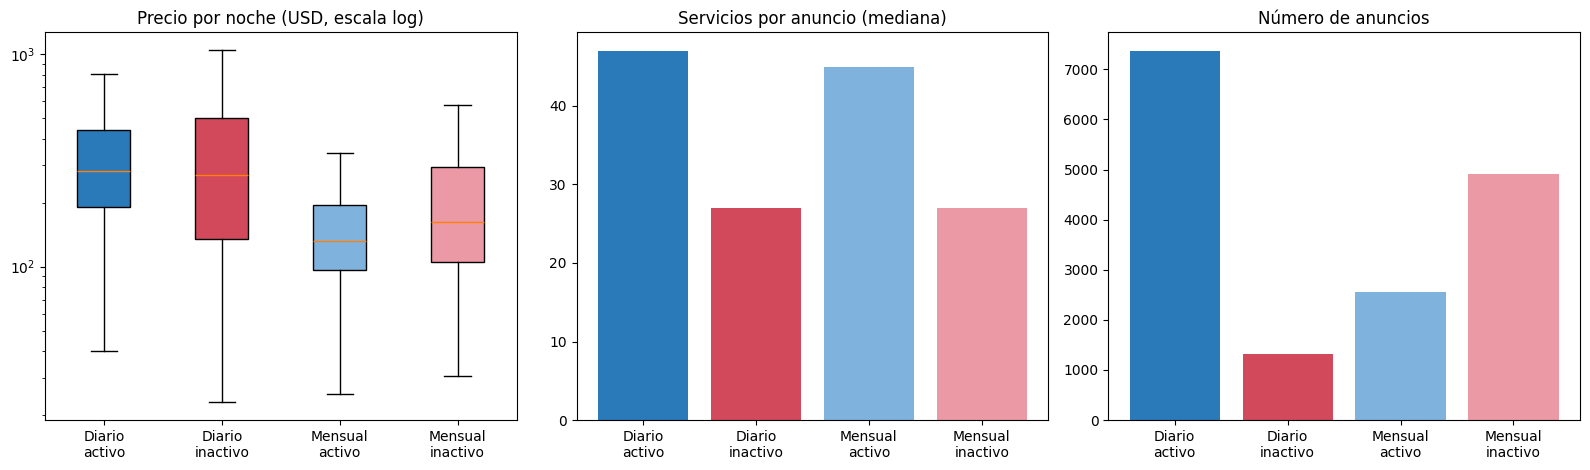

In [29]:
import matplotlib.pyplot as plt

names = list(groups)
labels = [n.replace(' · ', '\n') for n in names]
colors = ['#2a7ab9', '#d1495b', '#7fb3dd', '#eb9aa5']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

box = axes[0].boxplot([groups[n]['price_num'] for n in names], showfliers=False, patch_artist=True)
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
axes[0].set_xticks(range(1, len(names) + 1), labels)
axes[0].set_yscale('log')
axes[0].set_title('Precio por noche (USD, escala log)')

axes[1].bar(labels, [groups[n]['amenities_count'].median() for n in names], color=colors)
axes[1].set_title('Servicios por anuncio (mediana)')

axes[2].bar(labels, [len(groups[n]) for n in names], color=colors)
axes[2].set_title('Número de anuncios')

plt.tight_layout()
plt.show()

### 3.8 · Quitar columnas repetidas o constantes
En `df_diario` y `df_mensual` se eliminan:
- **Repetidas:** `is_inactive` (es lo contrario de `activo`) y `quote_is_monthly_priced` (igual a `is_monthly`).
- **Constantes por el filtro:** las marcas que se usaron para crear `df_limpio` y para dividirlo valen lo mismo en todas las filas (`is_small_host`, `has_price`, `is_hotel`, `price_outlier`, `is_monthly`, `in_target_market`).
- **Vacía en `df_mensual`:** `base_nightly_rate`, que solo existe con precio diario.

Al final se verifica que no quede ninguna columna constante.

In [30]:
REDUNDANT = ['is_inactive', 'quote_is_monthly_priced']
FILTER_FLAGS = ['is_small_host', 'has_price', 'is_hotel', 'price_outlier', 'is_monthly', 'in_target_market']

for name in ['df_diario', 'df_mensual']:
    data = globals()[name]
    drop = REDUNDANT + FILTER_FLAGS
    if name == 'df_mensual':
        drop = drop + ['base_nightly_rate']
    constant = [c for c in FILTER_FLAGS if data[c].nunique(dropna=False) == 1]
    assert constant == FILTER_FLAGS, f'{name}: estas marcas no son constantes: {set(FILTER_FLAGS) - set(constant)}'
    data = data.drop(columns=drop)

    still_constant = [c for c in data.columns if data[c].nunique(dropna=False) <= 1]
    assert not still_constant, f'{name}: quedan columnas constantes: {still_constant}'
    globals()[name] = data
    print(f'{name}: {data.shape}  (se quitaron {len(drop)} columnas)')

df_diario: (8690, 64)  (se quitaron 8 columnas)
df_mensual: (7468, 63)  (se quitaron 9 columnas)


## 4 · Análisis de variables y del precio
Esta sección reorganiza el análisis de Daniel Babativa (rama `daniel-babativa`) en este orden:

1. **Correlación** de cada variable con el **precio original** (`price_num`).
2. **Limpieza de variables:** de cada pareja muy correlacionada se deja solo la que mejor explica el precio.
3. **ANOVA** del precio original entre los 4 grupos (diario/mensual × activo/inactivo): qué grupos son distintos y cuáles se pueden unir.
4. **Distribución** del precio de cada grupo resultante (precio original vs. logaritmo), con gráficas y pruebas estadísticas.
5. **DataFrames finales** para el modelo.

Se trabaja sobre `df_limpio` (16.158 anuncios: hosts con 1–2 anuncios, con precio, sin hoteles ni precios extremos).

### 4.1 · Correlación de cada variable con el precio original
**Variables candidatas a predictor.** Antes de medir correlaciones se dejan fuera, por definición, las columnas que no pueden ser predictores:

| Columna | Por qué no es predictor |
|---|---|
| `id` | Identificador, no describe la propiedad. |
| `base_nightly_rate` | Es otra medida del precio (variable objetivo alternativa): usarla filtraría la respuesta. |
| Actividad: `number_of_reviews`, `number_of_reviews_ltm`, `last_review`, `availability_365`, `estimated_occupancy_l365d`, `has_availability` | Resultados de operar el anuncio; un anfitrión nuevo no los conoce. |
| `bedrooms_original`, `beds_original`, `*_imputed`, `bedrooms_gt_guests` | Control de calidad de la limpieza. |
| `bathrooms_text` | Texto: ya está convertido en `bathrooms` y `bathroom_shared`. |
| `neighbourhood_cleansed`, `property_type` | Versiones sin agrupar: se usan `neighbourhood_model` y `property_type_model`. |
| `calculated_host_listings_count`, marcas de limpieza, `activo` | Filtros de la población, no características de la propiedad. |

**Medidas de correlación:**
- Variables numéricas y servicios (0/1): **Pearson** y **Spearman**. Como el precio es muy asimétrico (sección 3.7), el criterio para decidir es **Spearman**, que usa rangos y no se deja arrastrar por los precios extremos.
- Variables categóricas: **razón de correlación η (eta)**, que mide qué parte de la variación del precio explican las categorías (η² = proporción explicada).

In [31]:
from scipy import stats

am_cols = [c for c in df_limpio.columns if c.startswith('am_')]
NUMERIC_CANDIDATES = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'bathroom_shared', 'amenities_count',
                      'minimum_nights', 'maximum_nights', 'quote_nights', 'latitude', 'longitude'] + am_cols
CATEGORICAL_CANDIDATES = ['neighbourhood_model', 'neighbourhood_group_cleansed', 'property_type_model', 'room_type']

price = df_limpio['price_num']

def correlation_ratio(categories, values):
    # η: raíz de la proporción de la varianza de `values` explicada por las categorías
    groups = values.groupby(categories)
    between = (groups.count() * (groups.mean() - values.mean()) ** 2).sum()
    total = ((values - values.mean()) ** 2).sum()
    return np.sqrt(between / total)

corr_table = pd.DataFrame({
    'tipo': 'numérica',
    'Pearson': df_limpio[NUMERIC_CANDIDATES].corrwith(price),
    'Spearman': df_limpio[NUMERIC_CANDIDATES].corrwith(price, method='spearman'),
})
cat_table = pd.DataFrame({
    'tipo': 'categórica',
    'eta (η)': [correlation_ratio(df_limpio[c], price) for c in CATEGORICAL_CANDIDATES],
}, index=CATEGORICAL_CANDIDATES)
corr_table = pd.concat([corr_table, cat_table])
corr_table['fuerza (|Spearman| o η)'] = corr_table['Spearman'].abs().fillna(corr_table['eta (η)'])
corr_table = corr_table.sort_values('fuerza (|Spearman| o η)', ascending=False)
corr_table.round(3)

,tipo,Pearson,Spearman,eta (η),fuerza (|Spearman| o η)
accommodates,numérica,0.600,0.704,NaN,0.704
bedrooms,numérica,0.603,0.642,NaN,0.642
beds,numérica,0.514,0.623,NaN,0.623
bathrooms,numérica,0.652,0.593,NaN,0.593
property_type_model,categórica,NaN,NaN,0.507,0.507
neighbourhood_model,categórica,NaN,NaN,0.412,0.412
am_dishwasher,numérica,0.263,0.346,NaN,0.346
minimum_nights,numérica,-0.161,-0.336,NaN,0.336
quote_nights,numérica,-0.162,-0.335,NaN,0.335
amenities_count,numérica,0.233,0.332,NaN,0.332


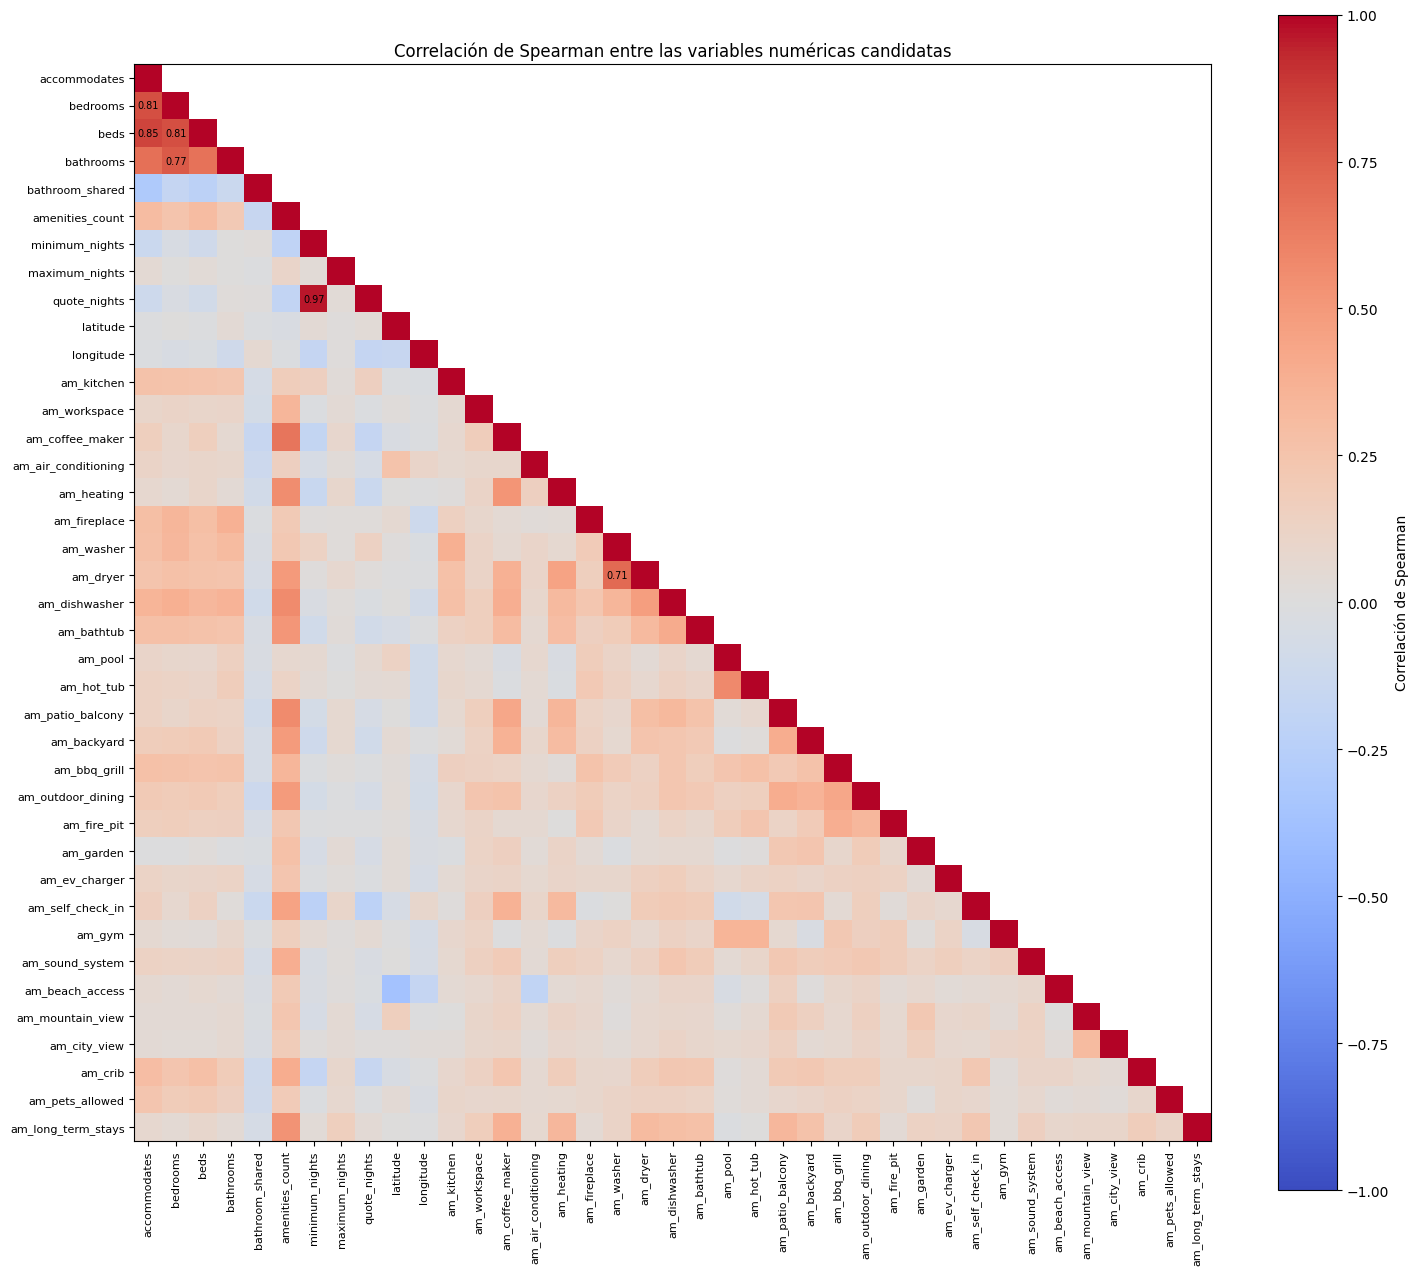

In [32]:
import matplotlib.pyplot as plt

# Correlación de Spearman entre las variables numéricas (mitad inferior); se rotulan las parejas con |ρ| ≥ 0,7
spearman_matrix = df_limpio[NUMERIC_CANDIDATES].corr(method='spearman')
values = spearman_matrix.to_numpy()
masked = np.ma.masked_where(np.triu(np.ones_like(values, dtype=bool), k=1) | ~np.isfinite(values), values)
cmap = plt.get_cmap('coolwarm').copy()
cmap.set_bad('white')

n_vars = len(NUMERIC_CANDIDATES)
fig, ax = plt.subplots(figsize=(15, 13))
image = ax.imshow(masked, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(n_vars), NUMERIC_CANDIDATES, rotation=90, fontsize=8)
ax.set_yticks(range(n_vars), NUMERIC_CANDIDATES, fontsize=8)
for i in range(n_vars):
    for j in range(i):
        if abs(values[i, j]) >= 0.7:
            ax.text(j, i, f'{values[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(image, ax=ax, label='Correlación de Spearman')
ax.set_title('Correlación de Spearman entre las variables numéricas candidatas')
plt.tight_layout()
plt.show()

### 4.2 · Dejar solo la variable que mejor explica el precio
**Regla:** si dos variables tienen una correlación de **|ρ| ≥ 0,8** entre ellas, se conserva la que tiene **mayor |Spearman| con el precio original** y se elimina la otra. Las parejas se revisan de la más correlacionada a la menos.

**Excepción:** `accommodates` (capacidad) y `bedrooms` (habitaciones) son características obligatorias del Project Charter y entradas del tablero, así que no se eliminan aunque estén correlacionadas entre sí; la pareja se reporta.

**Categóricas anidadas:** si dos variables categóricas tienen una asociación de **V de Cramér ≥ 0,8** (una casi determina a la otra), se conserva la de mayor η con el precio.

In [33]:
CORR_THRESHOLD = 0.8
PROTECTED = {'accommodates', 'bedrooms'}            # características obligatorias del Project Charter
strength = corr_table['fuerza (|Spearman| o η)']

# Parejas numéricas muy correlacionadas, de mayor a menor
pairs = []
for i, a in enumerate(NUMERIC_CANDIDATES):
    for b in NUMERIC_CANDIDATES[i + 1:]:
        rho = spearman_matrix.loc[a, b]
        if abs(rho) >= CORR_THRESHOLD:
            pairs.append((a, b, rho))

# Parejas categóricas: V de Cramér
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

for i, a in enumerate(CATEGORICAL_CANDIDATES):
    for b in CATEGORICAL_CANDIDATES[i + 1:]:
        v = cramers_v(df_limpio[a], df_limpio[b])
        if v >= CORR_THRESHOLD:
            pairs.append((a, b, v))

dropped, decisions = set(), []
for a, b, assoc in sorted(pairs, key=lambda t: -abs(t[2])):
    if a in dropped or b in dropped:
        decisions.append((a, b, assoc, '—', 'Ya se eliminó una de las dos'))
        continue
    if {a, b} <= PROTECTED:
        decisions.append((a, b, assoc, '—', 'Se conservan ambas (Project Charter)'))
        continue
    keep, drop = (a, b) if strength[a] >= strength[b] else (b, a)
    if drop in PROTECTED:
        keep, drop = drop, keep
    dropped.add(drop)
    decisions.append((a, b, assoc, drop, f'Se conserva {keep} ({strength[keep]:.3f} vs {strength[drop]:.3f})'))

decision_table = pd.DataFrame(decisions, columns=['variable 1', 'variable 2', 'asociación', 'se elimina', 'motivo'])
display(decision_table.round(3))

SELECTED_NUMERIC = [c for c in NUMERIC_CANDIDATES if c not in dropped]
SELECTED_CATEGORICAL = [c for c in CATEGORICAL_CANDIDATES if c not in dropped]
SELECTED_FEATURES = SELECTED_NUMERIC + SELECTED_CATEGORICAL
print(f'Variables eliminadas ({len(dropped)}): {sorted(dropped)}')
print(f'Variables seleccionadas ({len(SELECTED_FEATURES)}): {len(SELECTED_NUMERIC)} numéricas y {len(SELECTED_CATEGORICAL)} categóricas')
print(SELECTED_FEATURES)

,variable 1,variable 2,asociación,se elimina,motivo
0,property_type_model,room_type,1.000,room_type,Se conserva property_type_model (0.507 vs 0.281)
1,neighbourhood_model,neighbourhood_group_cleansed,0.991,neighbourhood_group_cleansed,Se conserva neighbourhood_model (0.412 vs 0.033)
2,minimum_nights,quote_nights,0.968,quote_nights,Se conserva minimum_nights (0.336 vs 0.335)
3,accommodates,beds,0.851,beds,Se conserva accommodates (0.704 vs 0.623)
4,accommodates,bedrooms,0.810,—,Se conservan ambas (Project Charter)
5,bedrooms,beds,0.808,—,Ya se eliminó una de las dos


Variables eliminadas (4): ['beds', 'neighbourhood_group_cleansed', 'quote_nights', 'room_type']
Variables seleccionadas (39): 37 numéricas y 2 categóricas
['accommodates', 'bedrooms', 'bathrooms', 'bathroom_shared', 'amenities_count', 'minimum_nights', 'maximum_nights', 'latitude', 'longitude', 'am_kitchen', 'am_workspace', 'am_coffee_maker', 'am_air_conditioning', 'am_heating', 'am_fireplace', 'am_washer', 'am_dryer', 'am_dishwasher', 'am_bathtub', 'am_pool', 'am_hot_tub', 'am_patio_balcony', 'am_backyard', 'am_bbq_grill', 'am_outdoor_dining', 'am_fire_pit', 'am_garden', 'am_ev_charger', 'am_self_check_in', 'am_gym', 'am_sound_system', 'am_beach_access', 'am_mountain_view', 'am_city_view', 'am_crib', 'am_pets_allowed', 'am_long_term_stays', 'neighbourhood_model', 'property_type_model']


### 4.3 · ANOVA: ¿los precios de los 4 grupos son diferentes?
Se compara el **precio original** entre los 4 grupos de la sección 3.7:

| Prueba | Pregunta |
|---|---|
| **ANOVA de una vía** | ¿Las medias de los 4 grupos son iguales? |
| **Levene** | ¿Las varianzas son iguales? (supuesto del ANOVA clásico) |
| **ANOVA de Welch** | Igual que el ANOVA, pero sin suponer varianzas iguales |
| **Kruskal-Wallis** | Versión no paramétrica (no supone normalidad) |
| **Tukey HSD** y **t de Welch con corrección de Bonferroni** | ¿Qué parejas de grupos son distintas? |
| **d de Cohen** | ¿Qué tan grande es la diferencia? (0,2 pequeña, 0,5 mediana, 0,8 grande) |

**Regla para unir grupos:** con miles de datos, casi cualquier diferencia sale estadísticamente significativa, aunque sea mínima. Por eso dos grupos se **unen** si la diferencia **no es significativa** (Bonferroni, α = 0,05) **o** si su tamaño es **despreciable** (|d de Cohen| < 0,2). Si es significativa y de tamaño al menos pequeño, se **separan**.

In [34]:
df_limpio['grupo'] = (np.where(df_limpio['is_monthly'] == 1, 'Mensual', 'Diario') + ' · '
                      + np.where(df_limpio['activo'] == 1, 'activo', 'inactivo'))
GROUP_ORDER = ['Diario · activo', 'Diario · inactivo', 'Mensual · activo', 'Mensual · inactivo']
samples = {g: df_limpio.loc[df_limpio['grupo'] == g, 'price_num'].to_numpy() for g in GROUP_ORDER}

summary = pd.DataFrame({g: {'anuncios': len(s), 'media': s.mean(), 'mediana': np.median(s),
                            'desviación': s.std(ddof=1)} for g, s in samples.items()}).T
display(summary.round(1))

def welch_anova(groups):
    n = np.array([len(g) for g in groups]); m = np.array([g.mean() for g in groups])
    w = n / np.array([g.var(ddof=1) for g in groups]); k = len(groups)
    mean_w = (w * m).sum() / w.sum()
    a = (w * (m - mean_w) ** 2).sum() / (k - 1)
    tmp = ((1 - w / w.sum()) ** 2 / (n - 1)).sum()
    f = a / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df2 = (k ** 2 - 1) / (3 * tmp)
    return f, k - 1, df2, stats.f.sf(f, k - 1, df2)

groups = list(samples.values())
anova = stats.f_oneway(*groups)
levene = stats.levene(*groups)
f_w, df1_w, df2_w, p_w = welch_anova(groups)
kruskal = stats.kruskal(*groups)
global_tests = pd.DataFrame({
    'estadístico': [anova.statistic, levene.statistic, f_w, kruskal.statistic],
    'valor p': [anova.pvalue, levene.pvalue, p_w, kruskal.pvalue],
}, index=['ANOVA de una vía (F)', 'Levene (varianzas iguales)', 'ANOVA de Welch (F)', 'Kruskal-Wallis (H)'])
global_tests['conclusión (α = 0,05)'] = np.where(global_tests['valor p'] < 0.05, 'Se rechaza H0', 'No se rechaza H0')
global_tests

,anuncios,media,mediana,desviación
Diario · activo,7370.0,361.3,281.4,276.0
Diario · inactivo,1320.0,411.5,270.3,417.4
Mensual · activo,2548.0,172.4,132.0,148.5
Mensual · inactivo,4920.0,266.9,162.8,300.4


,estadístico,valor p,"conclusión (α = 0,05)"
ANOVA de una vía (F),376.282050,2.976475e-236,Se rechaza H0
Levene (varianzas iguales),189.420481,9.928761e-121,Se rechaza H0
ANOVA de Welch (F),683.651856,0.000000e+00,Se rechaza H0
Kruskal-Wallis (H),2566.302904,0.000000e+00,Se rechaza H0


In [35]:
from itertools import combinations

tukey = stats.tukey_hsd(*groups)
n_pairs = len(GROUP_ORDER) * (len(GROUP_ORDER) - 1) // 2
rows = []
for (i, a), (j, b) in combinations(enumerate(GROUP_ORDER), 2):
    x, y = samples[a], samples[b]
    pooled_sd = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    d = (x.mean() - y.mean()) / pooled_sd
    p_welch = min(stats.ttest_ind(x, y, equal_var=False).pvalue * n_pairs, 1.0)    # Bonferroni
    significant = p_welch < 0.05
    merge = (not significant) or abs(d) < 0.2
    rows.append({'grupo 1': a, 'grupo 2': b, 'diferencia de medias': x.mean() - y.mean(),
                 'p Tukey': tukey.pvalue[i, j], 'p Welch (Bonferroni)': p_welch, 'd de Cohen': d,
                 'decisión': 'Unir' if merge else 'Separar'})
pairwise = pd.DataFrame(rows)
display(pairwise.round(4))

# Unir los grupos conectados por una decisión "Unir"
parent = {g: g for g in GROUP_ORDER}
def find(g):
    while parent[g] != g:
        g = parent[g]
    return g
for _, r in pairwise[pairwise['decisión'] == 'Unir'].iterrows():
    parent[find(r['grupo 2'])] = find(r['grupo 1'])

clusters = {}
for g in GROUP_ORDER:
    clusters.setdefault(find(g), []).append(g)
def cluster_name(members):
    if len(members) == 1:
        return members[0]
    kinds = {m.split(' · ')[0] for m in members}
    return kinds.pop() if len(kinds) == 1 else ' + '.join(members)
GROUP_MAP = {m: cluster_name(ms) for ms in clusters.values() for m in ms}
df_limpio['grupo_precio'] = df_limpio['grupo'].map(GROUP_MAP)

print('Grupos de precio resultantes:')
print(df_limpio['grupo_precio'].value_counts().reindex(dict.fromkeys(GROUP_MAP.values())).to_string())

,grupo 1,grupo 2,diferencia de medias,p Tukey,p Welch (Bonferroni),d de Cohen,decisión
0,Diario · activo,Diario · inactivo,-50.2273,0.0,0.0002,-0.1665,Unir
1,Diario · activo,Mensual · activo,188.9389,0.0,0.0000,0.7572,Separar
2,Diario · activo,Mensual · inactivo,94.3497,0.0,0.0000,0.3299,Separar
3,Diario · inactivo,Mensual · activo,239.1662,0.0,0.0000,0.8793,Separar
4,Diario · inactivo,Mensual · inactivo,144.5771,0.0,0.0000,0.4399,Separar
5,Mensual · activo,Mensual · inactivo,-94.5892,0.0,0.0000,-0.3654,Separar


Grupos de precio resultantes:
grupo_precio
Diario                8690
Mensual · activo      2548
Mensual · inactivo    4920


### 4.4 · ¿A qué distribución se ajusta el precio de cada grupo?
Para cada grupo resultante se compara el **precio original** y su **logaritmo** contra una distribución normal:

- **Asimetría:** 0 = simétrica; mientras más lejos de 0, más cola hacia un lado.
- **Kolmogorov-Smirnov (KS):** distancia máxima *D* entre la distribución de los datos y la normal ajustada (menor = más parecida), con su valor p.
- **Shapiro-Wilk:** estadístico *W* (1 = normal perfecta), sobre una muestra de hasta 5.000 datos.
- **Gráficas:** histograma con la normal ajustada, Q-Q (cuantiles) y P-P (probabilidades).

**Recomendación:** se usa el **logaritmo** si acerca la asimetría a 0 **y** reduce la distancia KS; si no, se deja el precio original.

> Con miles de datos, KS y Shapiro-Wilk rechazan la normalidad exacta casi siempre (valor p ≈ 0) aunque la aproximación sea muy buena. Por eso la decisión se basa en **D, W, la asimetría y las gráficas**, no solo en el valor p. Además, como la media y la desviación se estiman de los mismos datos, el valor p de KS es solo aproximado.

In [36]:
rng = np.random.default_rng(SEED)

def normality(values):
    mu, sd = values.mean(), values.std(ddof=1)
    ks = stats.kstest(values, stats.norm(mu, sd).cdf)
    sample = rng.choice(values, size=min(len(values), 5000), replace=False)
    sw = stats.shapiro(sample)
    return {'asimetría': stats.skew(values), 'KS D': ks.statistic, 'KS valor p': ks.pvalue,
            'Shapiro W': sw.statistic, 'Shapiro valor p': sw.pvalue}

PRICE_GROUPS = list(dict.fromkeys(GROUP_MAP.values()))
dist_rows, recommendations = [], {}
for g in PRICE_GROUPS:
    p = df_limpio.loc[df_limpio['grupo_precio'] == g, 'price_num'].to_numpy()
    original, logged = normality(p), normality(np.log(p))
    use_log = abs(logged['asimetría']) < abs(original['asimetría']) and logged['KS D'] < original['KS D']
    recommendations[g] = 'logaritmo' if use_log else 'original'
    dist_rows.append({'grupo': g, 'escala': 'precio original', **original})
    dist_rows.append({'grupo': g, 'escala': 'log(precio)', **logged})

distribution_table = pd.DataFrame(dist_rows).set_index(['grupo', 'escala'])
display(distribution_table.round(4))
print('Recomendación por grupo:')
for g, rec in recommendations.items():
    print(f'  {g}: usar el precio {"en logaritmo" if rec == "logaritmo" else "original"}')

asimetría    KS D  KS valor p  Shapiro W  \
grupo              escala                                                      
Diario             precio original     2.5192  0.1598      0.0000     0.7609   
                   log(precio)         0.1766  0.0224      0.0003     0.9962   
Mensual · activo   precio original     4.5454  0.1968      0.0000     0.6158   
                   log(precio)         0.6801  0.0595      0.0000     0.9744   
Mensual · inactivo precio original     3.1218  0.2233      0.0000     0.6374   
                   log(precio)         0.6809  0.0680      0.0000     0.9667   

                                    Shapiro valor p  
grupo              escala                            
Diario             precio original              0.0  
                   log(precio)                  0.0  
Mensual · activo   precio original              0.0  
                   log(precio)                  0.0  
Mensual · inactivo precio original              0.0  
                   log(precio)                  0.0

Recomendación por grupo:
  Diario: usar el precio en logaritmo
  Mensual · activo: usar el precio en logaritmo
  Mensual · inactivo: usar el precio en logaritmo


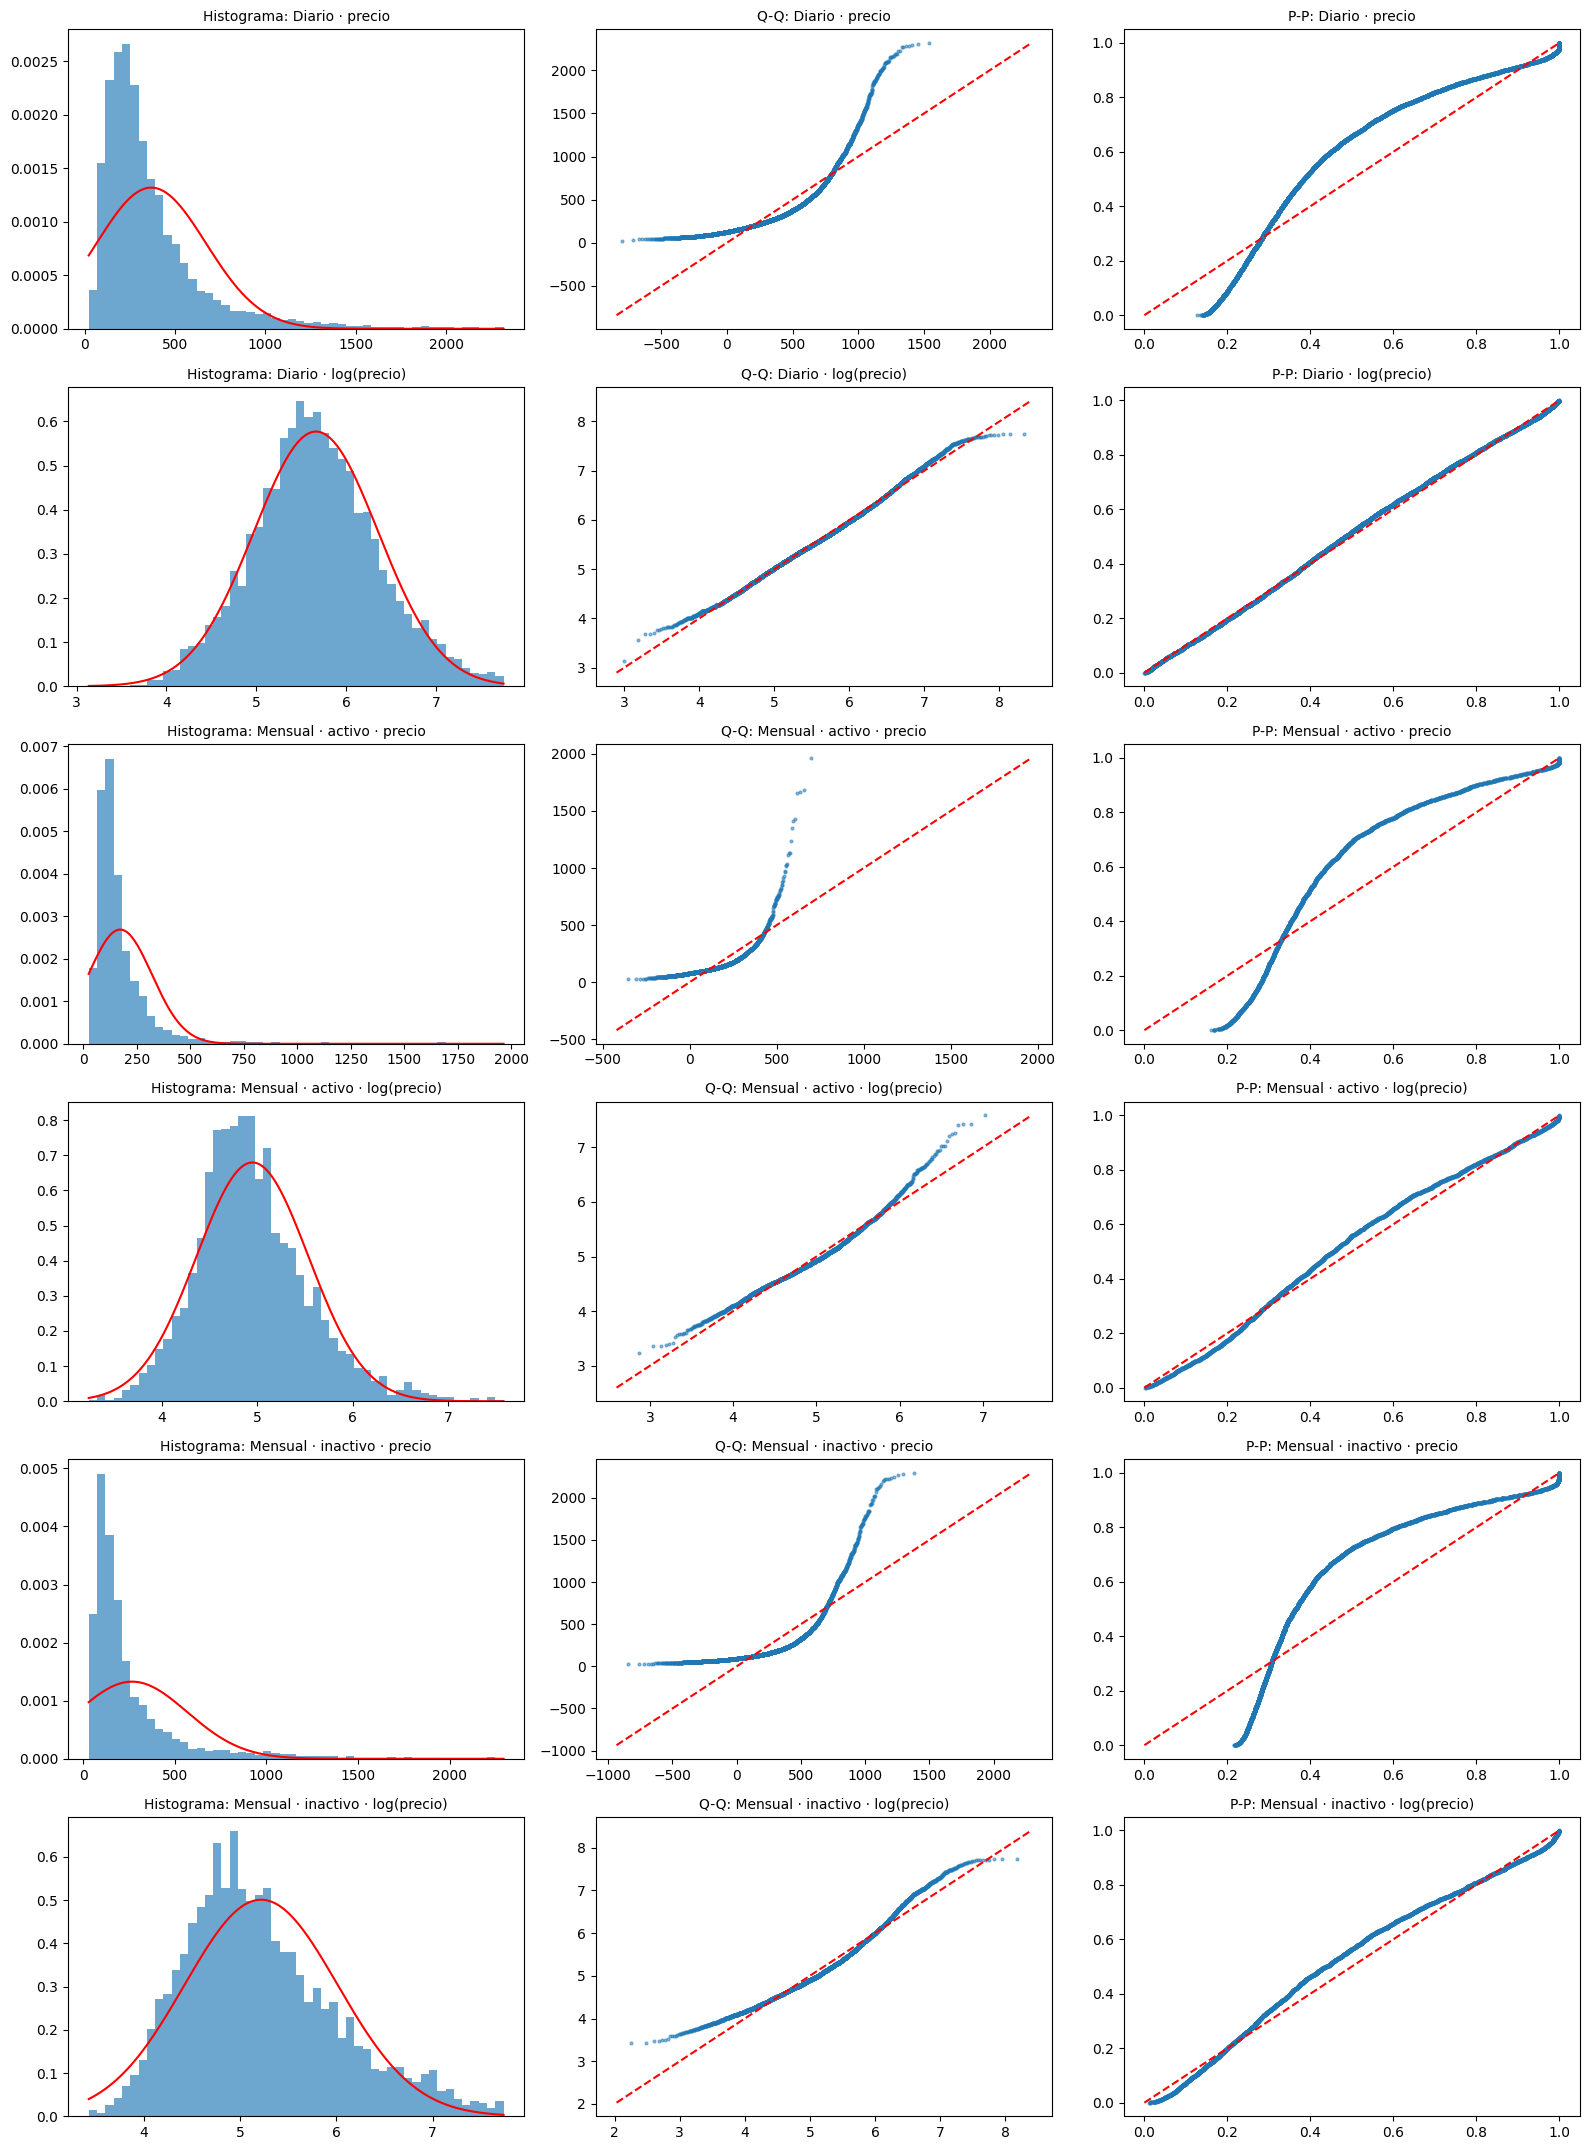

In [37]:
def plot_normality(ax_row, values, title):
    values = np.sort(values)
    mu, sd = values.mean(), values.std(ddof=1)
    probs = (np.arange(1, len(values) + 1) - 0.5) / len(values)
    ax_row[0].hist(values, bins=50, density=True, alpha=0.65)
    x = np.linspace(values.min(), values.max(), 300)
    ax_row[0].plot(x, stats.norm.pdf(x, mu, sd), 'r')
    ax_row[0].set_title(f'Histograma: {title}', fontsize=10)
    ax_row[1].scatter(stats.norm.ppf(probs, mu, sd), values, s=4, alpha=0.5)
    lims = [min(values.min(), mu - 4 * sd), max(values.max(), mu + 4 * sd)]
    ax_row[1].plot(lims, lims, 'r--')
    ax_row[1].set_title(f'Q-Q: {title}', fontsize=10)
    ax_row[2].scatter(stats.norm.cdf(values, mu, sd), probs, s=4, alpha=0.5)
    ax_row[2].plot([0, 1], [0, 1], 'r--')
    ax_row[2].set_title(f'P-P: {title}', fontsize=10)

fig, axes = plt.subplots(2 * len(PRICE_GROUPS), 3, figsize=(16, 3.6 * 2 * len(PRICE_GROUPS)))
for k, g in enumerate(PRICE_GROUPS):
    p = df_limpio.loc[df_limpio['grupo_precio'] == g, 'price_num'].to_numpy()
    plot_normality(axes[2 * k], p, f'{g} · precio')
    plot_normality(axes[2 * k + 1], np.log(p), f'{g} · log(precio)')
plt.tight_layout()
plt.show()

### 4.5 · DataFrames finales para el modelo
Se crea un DataFrame por **grupo de precio** resultante del ANOVA. Cada uno contiene:
- `id` y `grupo_precio`,
- `activo` (se conserva para poder filtrar, aunque el grupo junte activos e inactivos),
- la variable objetivo: `price_num` y, si la sección 4.4 lo recomienda, `price_log`,
- las **variables seleccionadas** en la sección 4.2.

In [38]:
# 10 anuncios no traen noches mínimas ni máximas. Mínimas = noches cotizadas (coinciden en el 93,5 % de los
# anuncios, sección 2); máximas = mediana del grupo. Se marca con nights_imputed.
df_limpio['nights_imputed'] = df_limpio['minimum_nights'].isna().astype(int)
df_limpio['minimum_nights'] = df_limpio['minimum_nights'].fillna(df_limpio['quote_nights'])
df_limpio['maximum_nights'] = df_limpio['maximum_nights'].fillna(
    df_limpio.groupby('grupo_precio')['maximum_nights'].transform('median'))
print(f"Noches mínimas/máximas rellenadas: {df_limpio['nights_imputed'].sum()} anuncios")

model_dfs = {}
for g in PRICE_GROUPS:
    data = df_limpio.loc[df_limpio['grupo_precio'] == g, ['id', 'grupo_precio', 'activo', 'price_num'] + SELECTED_FEATURES].copy()
    if recommendations[g] == 'logaritmo':
        data.insert(data.columns.get_loc('price_num') + 1, 'price_log', np.log(data['price_num']))
    constant = [c for c in SELECTED_FEATURES if data[c].nunique(dropna=False) <= 1]
    data = data.drop(columns=constant)                    # p. ej. variables que no varían dentro del grupo
    assert data[[c for c in data.columns if c in SELECTED_FEATURES]].isna().sum().sum() == 0, f'{g}: hay vacíos'
    model_dfs[g] = data.reset_index(drop=True)

NAMES = {g: 'df_modelo_' + g.lower().replace(' · ', '_').replace(' + ', '_y_').replace(' ', '_') for g in PRICE_GROUPS}
for g, name in NAMES.items():
    globals()[name] = model_dfs[g]
NAMES

Noches mínimas/máximas rellenadas: 10 anuncios


{'Diario': 'df_modelo_diario',
 'Mensual · activo': 'df_modelo_mensual_activo',
 'Mensual · inactivo': 'df_modelo_mensual_inactivo'}

In [39]:
# Shape y contenido de cada DataFrame resultante
for g, name in NAMES.items():
    data = model_dfs[g]
    target = 'price_log (logaritmo del precio)' if 'price_log' in data else 'price_num (precio original)'
    activos = int(data['activo'].sum())
    print(f'{name}: {data.shape}')
    print(f'  Contiene: anuncios del grupo "{g}" ({len(data):,} anuncios; {activos:,} activos y {len(data) - activos:,} inactivos).')
    print(f'  Variable objetivo recomendada: {target}.')
    print(f'  Predictores: {data.shape[1] - 4 - ("price_log" in data)} variables seleccionadas en 4.2.')
    print()

df_modelo_diario: (8690, 44)
  Contiene: anuncios del grupo "Diario" (8,690 anuncios; 7,370 activos y 1,320 inactivos).
  Variable objetivo recomendada: price_log (logaritmo del precio).
  Predictores: 39 variables seleccionadas en 4.2.

df_modelo_mensual_activo: (2548, 44)
  Contiene: anuncios del grupo "Mensual · activo" (2,548 anuncios; 2,548 activos y 0 inactivos).
  Variable objetivo recomendada: price_log (logaritmo del precio).
  Predictores: 39 variables seleccionadas en 4.2.

df_modelo_mensual_inactivo: (4920, 44)
  Contiene: anuncios del grupo "Mensual · inactivo" (4,920 anuncios; 0 activos y 4,920 inactivos).
  Variable objetivo recomendada: price_log (logaritmo del precio).
  Predictores: 39 variables seleccionadas en 4.2.



## 5 · Modelo de regresión (metodología del TEC)
Se repite **exactamente la metodología de regresión del equipo del TEC** (notebook `LA_LA_Stay_.ipynb` de la rama `main`, sección 4), aplicada a cada uno de los 3 DataFrames de la sección 4.5:

| Paso | Igual al TEC |
|---|---|
| Modelo | `Ridge` dentro de un `Pipeline` con `OneHotEncoder(handle_unknown='ignore')` para las categóricas |
| Variable objetivo | Precio por noche en dólares **sin transformar** (`price_num`) |
| División | 80 % entrenamiento / 20 % prueba, `random_state=42` |
| Elección de `alpha` | Validación cruzada de 3 partes (`KFold`, `shuffle=True`, `random_state=42`) sobre entrenamiento, con `alpha` ∈ {1, 10, 100} |
| Evaluación | MAE, RMSE y R² en prueba; meta de R² ≥ 0,30; precio real vs. predicción; distribución de errores; error por rango de precio |

**Lo único que cambia son los datos:** en lugar de su base (14.825 anuncios, 22 variables) se usan nuestros 3 grupos de precio y las **39 variables** seleccionadas en la sección 4.2.

### 5.1 · Preparar las variables

In [40]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NON_FEATURES = ['id', 'grupo_precio', 'activo', 'price_num', 'price_log']
datasets = {}
for g, name in NAMES.items():
    data = model_dfs[g]
    features = [c for c in data.columns if c not in NON_FEATURES]
    category_features = [c for c in features if data[c].dtype == 'object']
    data = data.dropna(subset=features + ['price_num'])           # igual que el TEC (normalmente no quita filas)
    datasets[name] = {'X': data[features], 'y': data['price_num'], 'category_features': category_features}
    print(f'{name}: {len(data):,} anuncios | {len(features)} variables '
          f'({len(features) - len(category_features)} numéricas, {len(category_features)} categóricas) | objetivo = price_num (USD)')

df_modelo_diario: 8,690 anuncios | 39 variables (37 numéricas, 2 categóricas) | objetivo = price_num (USD)
df_modelo_mensual_activo: 2,548 anuncios | 39 variables (37 numéricas, 2 categóricas) | objetivo = price_num (USD)
df_modelo_mensual_inactivo: 4,920 anuncios | 39 variables (37 numéricas, 2 categóricas) | objetivo = price_num (USD)


### 5.2 · Separar entrenamiento y prueba
El **80 %** se usa para aprender patrones y el **20 %** se reserva para medir qué tan bien predice el modelo propiedades que no vio.

In [41]:
for name, d in datasets.items():
    d['X_train'], d['X_test'], d['y_train'], d['y_test'] = train_test_split(
        d['X'], d['y'], test_size=0.20, random_state=SEED)
    print(f"{name}: train = {len(d['X_train']):,} | test = {len(d['X_test']):,}")

df_modelo_diario: train = 6,952 | test = 1,738
df_modelo_mensual_activo: train = 2,038 | test = 510
df_modelo_mensual_inactivo: train = 3,936 | test = 984


### 5.3 · Convertir los textos en variables numéricas
Ridge no entiende nombres de vecindarios directamente. `OneHotEncoder` crea indicadores numéricos y `handle_unknown='ignore'` permite recibir categorías nuevas en el futuro.

In [42]:
def tec_pipeline(category_features, alpha=1):
    preprocessor = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), category_features)
    ], remainder='passthrough')
    return Pipeline([('prepare', preprocessor), ('ridge', Ridge(alpha=alpha))])

for name, d in datasets.items():
    d['model'] = tec_pipeline(d['category_features'])
print('Ridge pipelines ready')

Ridge pipelines ready


### 5.4 · Comprobar si Ridge es una elección razonable
Se prueban distintas intensidades de regularización con **validación cruzada sobre entrenamiento**. El test permanece apartado, para no escoger el modelo mirando su calificación final.

DataFrame,df_modelo_diario,df_modelo_mensual_activo,df_modelo_mensual_inactivo
alpha,,,
1,0.6335,0.5448,0.5452
10,0.6359,0.5645,0.5537
100,0.6113,0.5442,0.5323


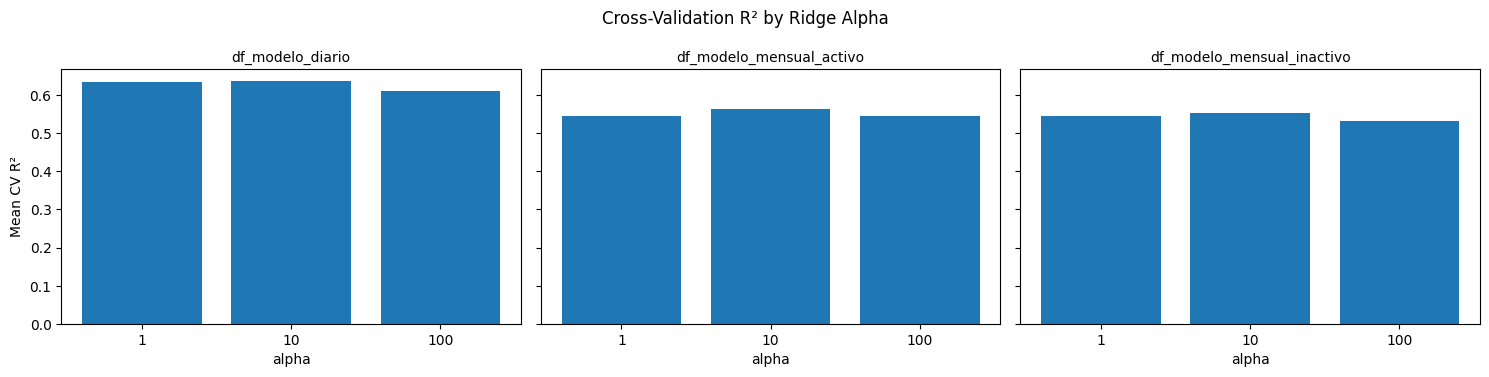

In [43]:
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for name, d in datasets.items():
    for alpha in [1, 10, 100]:
        d['model'].set_params(ridge__alpha=alpha)
        scores = cross_val_score(d['model'], d['X_train'], d['y_train'], cv=cv, scoring='r2')
        cv_rows.append({'DataFrame': name, 'alpha': alpha, 'CV_R2': scores.mean()})

cv_table = pd.DataFrame(cv_rows)
display(cv_table.pivot(index='alpha', columns='DataFrame', values='CV_R2').round(4))

fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 3.8), sharey=True)
for ax, (name, t) in zip(axes, cv_table.groupby('DataFrame', sort=False)):
    ax.bar(t['alpha'].astype(str), t['CV_R2'])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('alpha')
axes[0].set_ylabel('Mean CV R²')
fig.suptitle('Cross-Validation R² by Ridge Alpha')
plt.tight_layout()
plt.show()

**Interpretación:** el mejor `alpha` es el que obtuvo mayor R² promedio **solo en entrenamiento**. No es una garantía de que el R² final sea idéntico.

### 5.5 · Entrenar el modelo elegido

In [44]:
for name, d in datasets.items():
    t = cv_table[cv_table['DataFrame'] == name].sort_values('CV_R2', ascending=False)
    d['best_alpha'] = int(t.iloc[0]['alpha'])
    d['model'].set_params(ridge__alpha=d['best_alpha'])
    d['model'].fit(d['X_train'], d['y_train'])
    print(f"{name}: selected alpha = {d['best_alpha']} | model trained")

df_modelo_diario: selected alpha = 10 | model trained
df_modelo_mensual_activo: selected alpha = 10 | model trained
df_modelo_mensual_inactivo: selected alpha = 10 | model trained


### 5.6 · Predecir y evaluar
MAE y RMSE en dólares; R² indica qué proporción de la variación de precios se explica en **el conjunto de prueba**. Como referencia se incluye el resultado original del TEC con su base.

In [45]:
eval_rows = []
for name, d in datasets.items():
    d['y_pred'] = d['model'].predict(d['X_test'])
    r2 = r2_score(d['y_test'], d['y_pred'])
    eval_rows.append({'DataFrame': name, 'alpha': d['best_alpha'], 'train': len(d['X_train']), 'test': len(d['X_test']),
                      'MAE ($)': mean_absolute_error(d['y_test'], d['y_pred']),
                      'RMSE ($)': np.sqrt(mean_squared_error(d['y_test'], d['y_pred'])),
                      'R²': r2, 'R² ≥ 0.30': r2 >= 0.30,
                      'predicciones negativas': int((d['y_pred'] < 0).sum())})
eval_rows.append({'DataFrame': 'TEC original (su base)', 'alpha': 1, 'train': 11860, 'test': 2965,
                  'MAE ($)': 121.99, 'RMSE ($)': 193.93, 'R²': 0.5749, 'R² ≥ 0.30': True, 'predicciones negativas': np.nan})
evaluation = pd.DataFrame(eval_rows).set_index('DataFrame')
evaluation.round(4)

,alpha,train,test,MAE ($),RMSE ($),R²,R² ≥ 0.30,predicciones negativas
DataFrame,,,,,,,,
df_modelo_diario,10,6952,1738,121.4616,195.1673,0.6299,True,18.0
df_modelo_mensual_activo,10,2038,510,52.7370,96.0149,0.6115,True,2.0
df_modelo_mensual_inactivo,10,3936,984,115.2584,200.7133,0.5762,True,13.0
TEC original (su base),1,11860,2965,121.9900,193.9300,0.5749,True,NaN


**Cómo se explica:** si el MAE es $120, el error absoluto promedio es aproximadamente 120 dólares por noche. **R² no es un porcentaje de predicciones correctas**. Aunque sea mayor que 0,30, las recomendaciones siguen teniendo incertidumbre. Los R² de distintos DataFrames no son el mismo examen: cada uno se mide sobre su propio grupo de anuncios.

### 5.7 · Precio real vs. predicción
Mientras más cerca esté un punto de la diagonal, más cercana fue la predicción al precio real.

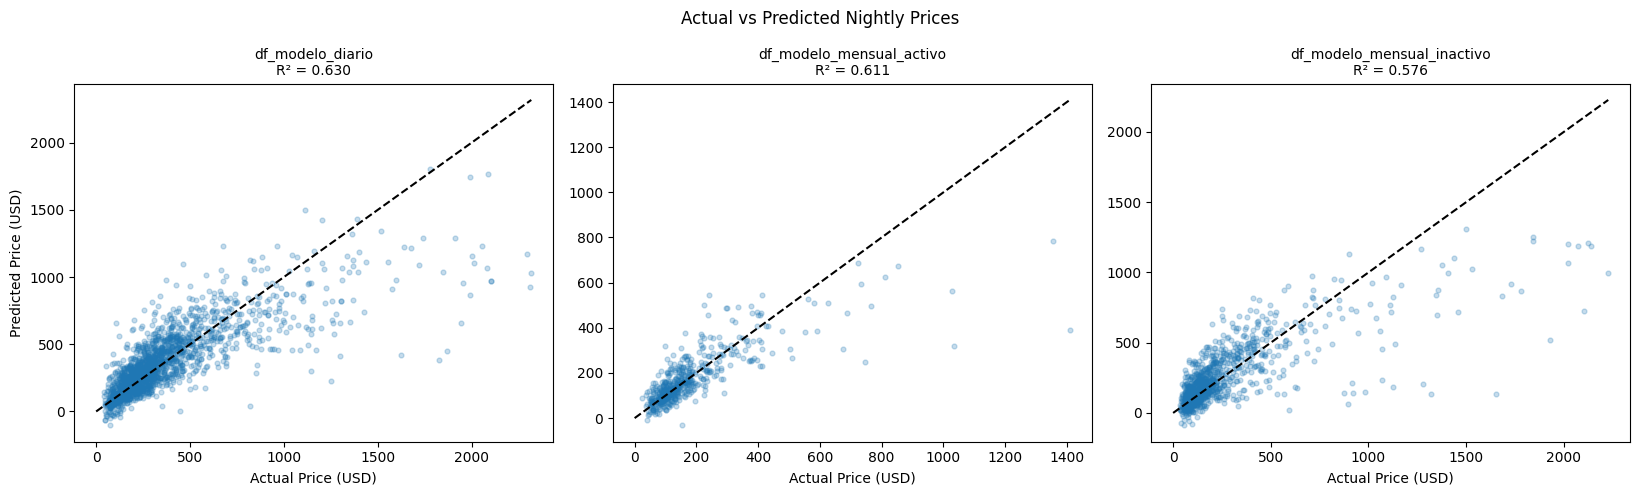

In [46]:
fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 5))
for ax, (name, d) in zip(axes, datasets.items()):
    ax.scatter(d['y_test'], d['y_pred'], alpha=0.25, s=12)
    limit = max(d['y_test'].max(), d['y_pred'].max())
    ax.plot([0, limit], [0, limit], '--', color='black')
    ax.set_title(f"{name}\nR² = {r2_score(d['y_test'], d['y_pred']):.3f}", fontsize=10)
    ax.set_xlabel('Actual Price (USD)')
axes[0].set_ylabel('Predicted Price (USD)')
fig.suptitle('Actual vs Predicted Nightly Prices')
plt.tight_layout()
plt.show()

### 5.8 · Distribución de los errores
El **residuo** es `precio real − predicción`. Un residuo positivo significa que el modelo predijo menos de lo publicado.

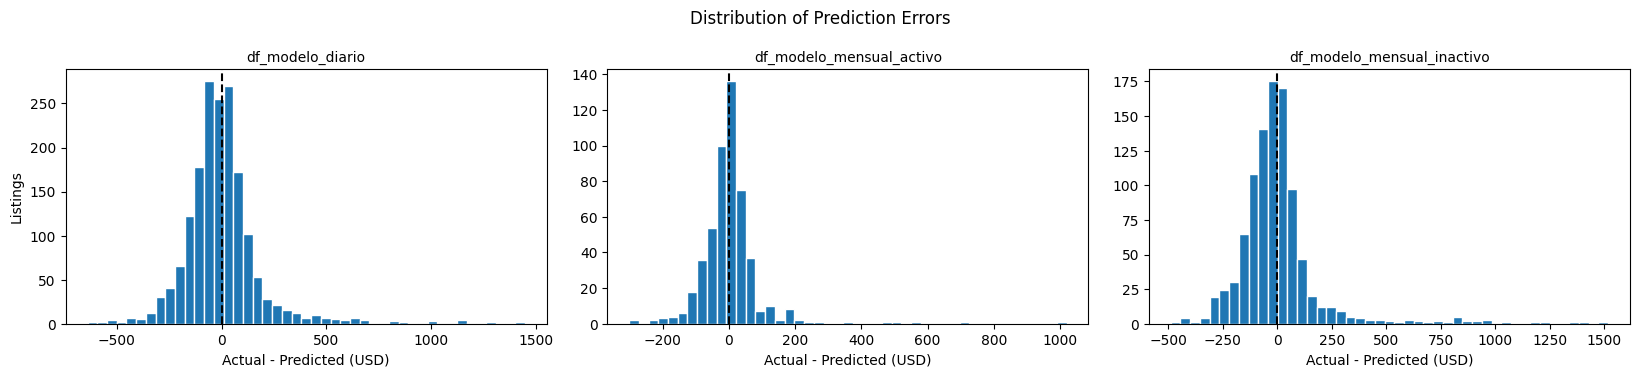

In [47]:
fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 3.8))
for ax, (name, d) in zip(axes, datasets.items()):
    residuals = d['y_test'] - d['y_pred']
    ax.hist(residuals, bins=45, edgecolor='white')
    ax.axvline(0, linestyle='--', color='black')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Actual - Predicted (USD)')
axes[0].set_ylabel('Listings')
fig.suptitle('Distribution of Prediction Errors')
plt.tight_layout()
plt.show()

### 5.9 · ¿Dónde nos equivocamos más?
Se dividen las propiedades de prueba por rango de precio (los mismos rangos del TEC) para ver si el error crece en los alojamientos más caros.

,df_modelo_diario,df_modelo_mensual_activo,df_modelo_mensual_inactivo
MAE (USD) by price range,,,
Up to $100,64.98,30.45,60.08
$100–250,74.61,43.24,74.04
$250–500,106.21,70.94,131.13
Over $500,247.69,300.29,388.95


,df_modelo_diario,df_modelo_mensual_activo,df_modelo_mensual_inactivo
Test listings by price range,,,
Up to $100,118,146,230
$100–250,628,279,457
$250–500,630,66,193
Over $500,362,19,104


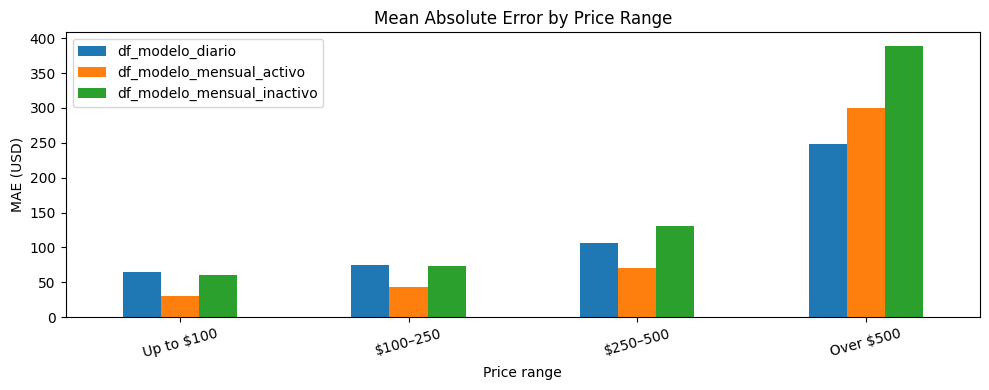

In [48]:
range_rows = {}
for name, d in datasets.items():
    error_df = pd.DataFrame({'Actual': d['y_test'], 'Error': abs(d['y_test'] - d['y_pred'])})
    error_df['Price range'] = pd.cut(error_df['Actual'], bins=[0, 100, 250, 500, np.inf],
                                     labels=['Up to $100', '$100–250', '$250–500', 'Over $500'])
    range_rows[name] = error_df.groupby('Price range', observed=False)['Error'].agg(['mean', 'count'])
error_by_range = pd.concat({n: t['mean'] for n, t in range_rows.items()}, axis=1)
listings_by_range = pd.concat({n: t['count'] for n, t in range_rows.items()}, axis=1)
display(error_by_range.round(2).rename_axis('MAE (USD) by price range'))
display(listings_by_range.rename_axis('Test listings by price range'))

error_by_range.plot(kind='bar', figsize=(10, 4))
plt.title('Mean Absolute Error by Price Range')
plt.ylabel('MAE (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretación:** el R² resume el rendimiento global, pero esta tabla muestra para qué tipo de propiedades el modelo se equivoca más. En el tablero conviene comunicar esa incertidumbre.

## 6 · Comparación de modelos con una misma semilla
Todos los modelos se entrenan y evalúan con **exactamente la misma división** de cada DataFrame (`SEED = 42`), para que la comparación sea justa:

| Paso | Detalle |
|---|---|
| División | 80 % entrenamiento / 20 % prueba (`random_state=SEED`), la misma de la sección 5 |
| Elección de hiperparámetros | Validación cruzada de 3 partes sobre entrenamiento (`KFold(3, shuffle=True, random_state=SEED)`) |
| Objetivo | Precio sin transformar y **log(precio)**; las predicciones con log se devuelven a dólares con `exp` |

| Modelo | Hiperparámetros probados |
|---|---|
| **Ridge** (como el TEC, sin estandarizar) | `alpha` ∈ {0,1; 1; 10; 100} |
| **Lasso** (variables estandarizadas, porque elimina variables según el tamaño de sus coeficientes) | sin log: `alpha` ∈ {0,01; 0,1; 1; 10}; con log: `alpha` ∈ {0,00001; 0,0001; 0,001; 0,01} |
| **XGBoost** (árboles con regularización) | 3 configuraciones de profundidad/regularización; el número de árboles se elige con parada temprana sobre una parte del entrenamiento |

**Métricas en prueba:** R² en dólares, R² ajustado (con las variables que el modelo realmente usa; no aplica a XGBoost), R² en escala log, MAE, error mediano, error porcentual medio y predicciones negativas.

> XGBoost requiere la librería `xgboost` (`pip install xgboost`). Si no está instalada, el notebook omite ese modelo y compara solo Ridge y Lasso.

In [49]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('xgboost no está instalado: se omite XGBoost')

cv_seed = KFold(n_splits=3, shuffle=True, random_state=SEED)

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan

def linear_pipeline(kind, alpha, numeric, categorical):
    if kind == 'Ridge':        # igual que el TEC: sin estandarizar
        prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                 remainder='passthrough')
        reg = Ridge(alpha=alpha)
    else:                      # Lasso: variables estandarizadas
        prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
                                  ('numeric', StandardScaler(), numeric)])
        reg = Lasso(alpha=alpha, max_iter=50_000)
    return Pipeline([('prepare', prep), ('model', reg)])

GRIDS = {('Ridge', False): [0.1, 1, 10, 100], ('Ridge', True): [0.1, 1, 10, 100],
         ('Lasso', False): [0.01, 0.1, 1, 10], ('Lasso', True): [1e-5, 1e-4, 1e-3, 1e-2]}
XGB_CONFIGS = [
    {'max_depth': 3, 'min_child_weight': 5, 'reg_lambda': 1},
    {'max_depth': 5, 'min_child_weight': 5, 'reg_lambda': 10},
    {'max_depth': 7, 'min_child_weight': 10, 'reg_lambda': 10},
]
XGB_COMMON = dict(learning_rate=0.03, subsample=0.7, colsample_bytree=0.5, n_estimators=4000,
                  early_stopping_rounds=150, tree_method='hist', random_state=SEED, n_jobs=-1)

In [50]:
comparison_rows = []
for name, d in datasets.items():
    X_train, X_test, y_train, y_test = d['X_train'], d['X_test'], d['y_train'], d['y_test']
    categorical = d['category_features']
    numeric = [c for c in X_train.columns if c not in categorical]
    n_test = len(y_test)

    for use_log in [False, True]:
        y_fit = np.log(y_train) if use_log else y_train
        back = np.exp if use_log else (lambda v: v)

        # Ridge y Lasso: alpha por validación cruzada de 3 partes
        for kind in ['Ridge', 'Lasso']:
            scores = {a: cross_val_score(linear_pipeline(kind, a, numeric, categorical), X_train, y_fit,
                                         cv=cv_seed, scoring='r2').mean() for a in GRIDS[(kind, use_log)]}
            best = max(scores, key=scores.get)
            model = linear_pipeline(kind, best, numeric, categorical).fit(X_train, y_fit)
            pred = back(model.predict(X_test))
            n_used = int((np.abs(model.named_steps['model'].coef_) > 1e-10).sum())
            comparison_rows.append((name, kind, use_log, best, n_used, pred))

        # XGBoost: configuración por validación cruzada; árboles por parada temprana
        if HAS_XGB:
            prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                     remainder='passthrough')
            A_train = prep.fit_transform(X_train).astype(float)
            A_test = prep.transform(X_test).astype(float)
            A_train = A_train.toarray() if hasattr(A_train, 'toarray') else A_train
            A_test = A_test.toarray() if hasattr(A_test, 'toarray') else A_test
            y_arr = np.asarray(y_fit)
            cv_scores = []
            for cfg in XGB_CONFIGS:
                fold_scores = []
                for tr, va in cv_seed.split(A_train):
                    m = xgb.XGBRegressor(**XGB_COMMON, **cfg).fit(A_train[tr], y_arr[tr],
                                                                 eval_set=[(A_train[va], y_arr[va])], verbose=False)
                    fold_scores.append(r2_score(y_arr[va], m.predict(A_train[va])))
                cv_scores.append(np.mean(fold_scores))
            cfg = XGB_CONFIGS[int(np.argmax(cv_scores))]
            A_fit, A_stop, y_fit_, y_stop = train_test_split(A_train, y_arr, test_size=0.2, random_state=SEED)
            m = xgb.XGBRegressor(**XGB_COMMON, **cfg).fit(A_fit, y_fit_, eval_set=[(A_stop, y_stop)], verbose=False)
            pred = back(m.predict(A_test))
            comparison_rows.append((name, 'XGBoost', use_log, f"depth={cfg['max_depth']}, árboles={m.best_iteration + 1}",
                                    np.nan, pred))

results = []
for name, kind, use_log, hyper, n_used, pred in comparison_rows:
    y_test = datasets[name]['y_test']
    r2 = r2_score(y_test, pred)
    results.append({
        'DataFrame': name, 'modelo': kind, 'objetivo': 'log(precio)' if use_log else 'precio',
        'hiperparámetro': hyper, 'variables usadas': n_used,
        'R² USD': r2, 'R² ajustado': adjusted_r2(r2, len(y_test), n_used) if not np.isnan(n_used) else np.nan,
        'R² log': r2_score(np.log(y_test), np.log(np.clip(pred, 1, None))),
        'MAE ($)': mean_absolute_error(y_test, pred), 'error mediano ($)': np.median(np.abs(y_test - pred)),
        'error % medio': np.mean(np.abs(pred - y_test) / y_test) * 100, 'negativas': int((pred < 0).sum()),
    })
model_comparison = pd.DataFrame(results)
for name, t in model_comparison.groupby('DataFrame', sort=False):
    print(f'\n{name}  (test = {len(datasets[name]["y_test"]):,} anuncios)')
    display(t.drop(columns='DataFrame').round(3).reset_index(drop=True))


df_modelo_diario  (test = 1,738 anuncios)


,modelo,objetivo,hiperparámetro,variables usadas,R² USD,R² ajustado,R² log,MAE ($),error mediano ($),error % medio,negativas
0,Ridge,precio,10,269.0,0.630,0.562,0.163,121.462,77.391,38.179,18
1,Lasso,precio,0.1,158.0,0.627,0.590,0.134,121.966,77.355,38.320,18
2,XGBoost,precio,"depth=5, árboles=748",NaN,0.672,NaN,0.719,108.104,63.153,31.218,0
3,Ridge,log(precio),1,269.0,0.602,0.529,0.734,109.077,54.720,27.806,0
4,Lasso,log(precio),0.0001,222.0,0.603,0.545,0.734,108.908,54.744,27.703,0
5,XGBoost,log(precio),"depth=5, árboles=1314",NaN,0.666,NaN,0.752,101.950,54.215,26.263,0



df_modelo_mensual_activo  (test = 510 anuncios)


,modelo,objetivo,hiperparámetro,variables usadas,R² USD,R² ajustado,R² log,MAE ($),error mediano ($),error % medio,negativas
0,Ridge,precio,10,241.0,0.611,0.262,0.390,52.737,31.450,32.065,2
1,Lasso,precio,0.1,113.0,0.607,0.495,0.378,53.356,32.535,32.566,2
2,XGBoost,precio,"depth=5, árboles=205",NaN,0.608,NaN,0.705,47.154,24.673,27.206,0
3,Ridge,log(precio),10,241.0,0.633,0.302,0.753,44.938,23.066,23.169,0
4,Lasso,log(precio),0.001,77.0,0.629,0.563,0.741,45.553,23.118,23.875,0
5,XGBoost,log(precio),"depth=3, árboles=1300",NaN,0.611,NaN,0.760,44.301,21.591,22.661,0



df_modelo_mensual_inactivo  (test = 984 anuncios)


,modelo,objetivo,hiperparámetro,variables usadas,R² USD,R² ajustado,R² log,MAE ($),error mediano ($),error % medio,negativas
0,Ridge,precio,10,247.0,0.576,0.434,-0.009,115.258,67.397,52.989,13
1,Lasso,precio,0.1,149.0,0.568,0.490,-0.185,117.361,68.944,55.419,18
2,XGBoost,precio,"depth=7, árboles=185",NaN,0.625,NaN,0.626,99.860,46.897,41.275,0
3,Ridge,log(precio),10,247.0,0.592,0.455,0.664,94.687,38.800,33.090,0
4,Lasso,log(precio),0.0001,206.0,0.585,0.475,0.654,95.415,39.082,34.091,0
5,XGBoost,log(precio),"depth=5, árboles=378",NaN,0.611,NaN,0.664,93.626,36.077,32.194,0


In [51]:
# Mejor modelo de cada DataFrame según cada criterio
best_rows = []
for name, t in model_comparison.groupby('DataFrame', sort=False):
    label = lambda r: f"{r['modelo']} · {r['objetivo']}"
    best_rows.append({
        'DataFrame': name,
        'mayor R² USD': label(t.loc[t['R² USD'].idxmax()]) + f" ({t['R² USD'].max():.3f})",
        'mayor R² log': label(t.loc[t['R² log'].idxmax()]) + f" ({t['R² log'].max():.3f})",
        'menor MAE': label(t.loc[t['MAE ($)'].idxmin()]) + f" (${t['MAE ($)'].min():.0f})",
        'menor error %': label(t.loc[t['error % medio'].idxmin()]) + f" ({t['error % medio'].min():.1f} %)",
    })
pd.DataFrame(best_rows).set_index('DataFrame')

,mayor R² USD,mayor R² log,menor MAE,menor error %
DataFrame,,,,
df_modelo_diario,XGBoost · precio (0.672),XGBoost · log(precio) (0.752),XGBoost · log(precio) ($102),XGBoost · log(precio) (26.3 %)
df_modelo_mensual_activo,Ridge · log(precio) (0.633),XGBoost · log(precio) (0.760),XGBoost · log(precio) ($44),XGBoost · log(precio) (22.7 %)
df_modelo_mensual_inactivo,XGBoost · precio (0.625),XGBoost · log(precio) (0.664),XGBoost · log(precio) ($94),XGBoost · log(precio) (32.2 %)


## 7 · Modelos finales de regresión
Se construyen los dos modelos finales que se presentan:

| | Modelo | Qué se busca |
|---|---|---|
| **A** | **Ridge** (el modelo del equipo del TEC) | La mejor versión posible de Ridge con nuestros datos |
| **B** | **XGBoost** (modelo propuesto) | La mejor regresión con un modelo distinto |

**Cómo se elige "la mejor" versión, sin mirar la prueba:** cada configuración candidata se evalúa con **validación cruzada de 3 partes sobre los datos de entrenamiento** (`SEED = 42`), usando el **MAE en dólares** (error promedio por noche, el más fácil de interpretar para un anfitrión). La configuración ganadora se entrena con todo el entrenamiento y se evalúa **una sola vez** en la prueba.

**Prueba común:** los 3.232 anuncios de prueba de la sección 5 (unión de los tres grupos), iguales para los dos modelos y para la referencia del TEC.

### 7.1 · Entrenamiento y prueba comunes

In [52]:
def stack_split(part):
    frames = []
    for name, d in datasets.items():
        X = d[f'X_{part}'].copy()
        g = next(k for k, v in NAMES.items() if v == name)
        X['activo'] = model_dfs[g].loc[X.index, 'activo'].to_numpy()
        X['es_mensual'] = int(g != 'Diario')
        X['dataset'] = name
        X['price_num'] = d[f'y_{part}'].to_numpy()
        X.index = name + '_' + X.index.astype(str)       # índice único entre grupos
        frames.append(X)
    return pd.concat(frames)

train_all, test_all = stack_split('train'), stack_split('test')
BASE_FEATURES = [c for c in datasets['df_modelo_diario']['X_train'].columns]
CATEGORICAL = datasets['df_modelo_diario']['category_features']
GROUP_FLAGS = ['es_mensual', 'activo']
print(f'Entrenamiento: {len(train_all):,} anuncios | Prueba: {len(test_all):,} anuncios')
print(test_all['dataset'].value_counts().to_string())

Entrenamiento: 12,926 anuncios | Prueba: 3,232 anuncios
dataset
df_modelo_diario              1738
df_modelo_mensual_inactivo     984
df_modelo_mensual_activo       510


### 7.2 · Modelo A: la mejor versión de Ridge (modelo del TEC)
Se comparan 4 configuraciones de Ridge (siempre con `OneHotEncoder`, sin estandarizar, igual que el TEC):

| Configuración | Datos | Objetivo |
|---|---|---|
| Separados · precio | Un Ridge por grupo | Precio en USD (como el TEC) |
| Separados · log | Un Ridge por grupo | log(precio) |
| Un solo modelo · precio | Un Ridge para todos, con `es_mensual` y `activo` | Precio en USD |
| Un solo modelo · log | Un Ridge para todos, con `es_mensual` y `activo` | log(precio) |

En cada una, `alpha` ∈ {0,1; 1; 10; 100} se elige por validación cruzada (como el TEC).

In [53]:
from sklearn.model_selection import cross_val_predict

def ridge_fit(X, y, categorical):
    # alpha por validación cruzada de 3 partes (metodología del TEC)
    scores = {a: cross_val_score(tec_pipeline(categorical, a), X, y, cv=cv_seed, scoring='r2').mean()
              for a in [0.1, 1, 10, 100]}
    best = max(scores, key=scores.get)
    return tec_pipeline(categorical, best).fit(X, y), best

def ridge_setup(train, test, separate, use_log):
    # Devuelve predicciones fuera de muestra (CV) para entrenamiento y predicciones en prueba, en USD
    back = np.exp if use_log else (lambda v: v)
    features = BASE_FEATURES if separate else BASE_FEATURES + GROUP_FLAGS
    parts = [(train[train['dataset'] == n], test[test['dataset'] == n]) for n in datasets] if separate else [(train, test)]
    oof = pd.Series(index=train.index, dtype=float)
    pred = pd.Series(index=test.index, dtype=float)
    alphas = []
    for tr, te in parts:
        y = np.log(tr['price_num']) if use_log else tr['price_num']
        model, alpha = ridge_fit(tr[features], y, CATEGORICAL)
        oof.loc[tr.index] = back(cross_val_predict(tec_pipeline(CATEGORICAL, alpha), tr[features], y, cv=cv_seed))
        pred.loc[te.index] = back(model.predict(te[features]))
        alphas.append(alpha)
    return oof, pred, alphas

ridge_candidates = {}
for separate in [True, False]:
    for use_log in [False, True]:
        label = f"{'Separados' if separate else 'Un solo modelo'} · {'log' if use_log else 'precio'}"
        oof, pred, alphas = ridge_setup(train_all, test_all, separate, use_log)
        ridge_candidates[label] = {'oof': oof, 'pred': pred, 'alphas': alphas,
                                   'CV MAE ($)': mean_absolute_error(train_all['price_num'], oof)}

ridge_cv = pd.DataFrame({k: {'alpha': v['alphas'], 'CV MAE ($)': v['CV MAE ($)']} for k, v in ridge_candidates.items()}).T
ridge_cv['CV MAE ($)'] = ridge_cv['CV MAE ($)'].astype(float).round(2)
BEST_RIDGE = ridge_cv['CV MAE ($)'].idxmin()
display(ridge_cv.sort_values('CV MAE ($)'))
print(f'Modelo A elegido (menor MAE en validación cruzada): Ridge · {BEST_RIDGE}')

,alpha,CV MAE ($)
Separados · log,"[1, 10, 10]",89.74
Un solo modelo · log,[10],90.23
Separados · precio,"[10, 10, 10]",103.21
Un solo modelo · precio,[10],105.84


Modelo A elegido (menor MAE en validación cruzada): Ridge · Separados · log


### 7.3 · Modelo B: XGBoost (modelo propuesto)
**Qué es XGBoost.** Es un modelo de *gradient boosting*: construye cientos de **árboles de decisión pequeños, uno tras otro**, y cada árbol nuevo aprende a corregir los errores que dejaron los anteriores. La predicción final es la suma de todos los árboles.

**Por qué encaja con este problema:**
- **Relaciones no lineales e interacciones:** por ejemplo, una habitación extra no vale lo mismo en Malibú que en Lancaster. Ridge suma efectos fijos; los árboles combinan variables automáticamente.
- **Un solo modelo para los tres grupos:** con `es_mensual` y `activo` como variables, los árboles aprenden solos que los grupos tienen niveles de precio distintos (lo que el ANOVA mostró), y los grupos pequeños se benefician de los datos de los demás.
- **Regularización para no sobreajustar:** profundidad máxima de los árboles (`max_depth`), mínimo de datos por hoja (`min_child_weight`), penalización L2 de las hojas (`reg_lambda`), muestreo de filas y columnas por árbol (`subsample`, `colsample_bytree`) y **parada temprana**: se dejan de agregar árboles cuando el error deja de bajar en datos que el modelo no usa para aprender.
- **Objetivo en logaritmo:** el error queda en términos porcentuales (sección 4.4) y no hay precios negativos.

Se elige entre 3 configuraciones de regularización por validación cruzada (MAE en USD).

In [54]:
XGB_FEATURES = BASE_FEATURES + GROUP_FLAGS

def to_dense(m):
    return m.toarray() if hasattr(m, 'toarray') else m

if HAS_XGB:
    xgb_prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)],
                                 remainder='passthrough')
    A_train = to_dense(xgb_prep.fit_transform(train_all[XGB_FEATURES])).astype(float)
    A_test = to_dense(xgb_prep.transform(test_all[XGB_FEATURES])).astype(float)
    feature_names = [n.replace('categories__', '').replace('remainder__', '') for n in xgb_prep.get_feature_names_out()]
    y_log = np.log(train_all['price_num'].to_numpy())
    y_usd = train_all['price_num'].to_numpy()

    xgb_cv_rows = []
    for cfg in XGB_CONFIGS:
        oof = np.zeros(len(y_log))
        for tr, va in cv_seed.split(A_train):
            m = xgb.XGBRegressor(**XGB_COMMON, **cfg).fit(A_train[tr], y_log[tr],
                                                         eval_set=[(A_train[va], y_log[va])], verbose=False)
            oof[va] = np.exp(m.predict(A_train[va]))
        xgb_cv_rows.append({**cfg, 'CV MAE ($)': mean_absolute_error(y_usd, oof)})
    xgb_cv = pd.DataFrame(xgb_cv_rows)
    display(xgb_cv.round(2))
    BEST_XGB_CFG = XGB_CONFIGS[int(xgb_cv['CV MAE ($)'].idxmin())]

    # Entrenamiento final: el número de árboles se fija con parada temprana sobre el 20 % del entrenamiento
    A_fit, A_stop, y_fit, y_stop = train_test_split(A_train, y_log, test_size=0.2, random_state=SEED)
    final_xgb = xgb.XGBRegressor(**XGB_COMMON, **BEST_XGB_CFG).fit(A_fit, y_fit, eval_set=[(A_stop, y_stop)], verbose=False)
    xgb_pred = pd.Series(np.exp(final_xgb.predict(A_test)), index=test_all.index)
    print(f"Modelo B elegido: XGBoost · log(precio) · {BEST_XGB_CFG} · árboles = {final_xgb.best_iteration + 1}")
else:
    print('xgboost no está instalado: instala la librería para entrenar el modelo B')

,max_depth,min_child_weight,reg_lambda,CV MAE ($)
0,3,5,1,83.60
1,5,5,10,82.76
2,7,10,10,82.76


Modelo B elegido: XGBoost · log(precio) · {'max_depth': 5, 'min_child_weight': 5, 'reg_lambda': 10} · árboles = 1826


### 7.4 · Comparación final en prueba
Se comparan, sobre los mismos 3.232 anuncios de prueba:
- **Referencia:** Ridge del TEC tal cual (sección 5: un Ridge por grupo, precio sin transformar).
- **Modelo A:** la mejor versión de Ridge (7.2).
- **Modelo B:** XGBoost (7.3).

In [55]:
tec_reference = pd.concat([pd.Series(d['y_pred'], index=name + '_' + d['X_test'].index.astype(str))
                           for name, d in datasets.items()]).reindex(test_all.index)
final_models = {'Referencia: Ridge del TEC tal cual': tec_reference,
                f'Modelo A: Ridge · {BEST_RIDGE}': ridge_candidates[BEST_RIDGE]['pred']}
if HAS_XGB:
    final_models['Modelo B: XGBoost · log(precio)'] = xgb_pred

def final_metrics(y, p):
    return {'R²': r2_score(y, p), 'R² log': r2_score(np.log(y), np.log(np.clip(p, 1, None))),
            'MAE ($)': mean_absolute_error(y, p), 'RMSE ($)': np.sqrt(mean_squared_error(y, p)),
            'error mediano ($)': np.median(np.abs(y - p)), 'error % medio': np.mean(np.abs(p - y) / y) * 100,
            'negativas': int((p < 0).sum())}

final_rows = []
for model_name, pred in final_models.items():
    final_rows.append({'evaluado en': 'Todos', 'modelo': model_name, **final_metrics(test_all['price_num'], pred)})
    for name in datasets:
        mask = test_all['dataset'] == name
        final_rows.append({'evaluado en': name, 'modelo': model_name,
                           **final_metrics(test_all.loc[mask, 'price_num'], pred[mask])})
final_comparison = pd.DataFrame(final_rows).set_index(['evaluado en', 'modelo'])
final_comparison.round(3)

,,R²,R² log,MAE ($),RMSE ($),error mediano ($),error % medio,negativas
evaluado en,modelo,,,,,,,
Todos,Referencia: Ridge del TEC tal cual,0.635,0.242,108.728,184.940,66.247,41.723,33
df_modelo_diario,Referencia: Ridge del TEC tal cual,0.630,0.163,121.462,195.167,77.391,38.179,18
df_modelo_mensual_activo,Referencia: Ridge del TEC tal cual,0.611,0.390,52.737,96.015,31.450,32.065,2
df_modelo_mensual_inactivo,Referencia: Ridge del TEC tal cual,0.576,-0.009,115.258,200.713,67.397,52.989,13
Todos,Modelo A: Ridge · Separados · log,0.625,0.749,94.575,187.663,43.582,28.683,0
df_modelo_diario,Modelo A: Ridge · Separados · log,0.602,0.734,109.077,202.444,54.720,27.806,0
df_modelo_mensual_activo,Modelo A: Ridge · Separados · log,0.633,0.753,44.938,93.349,23.066,23.169,0
df_modelo_mensual_inactivo,Modelo A: Ridge · Separados · log,0.592,0.664,94.687,196.900,38.800,33.090,0
Todos,Modelo B: XGBoost · log(precio),0.676,0.769,88.400,174.342,40.715,27.016,0


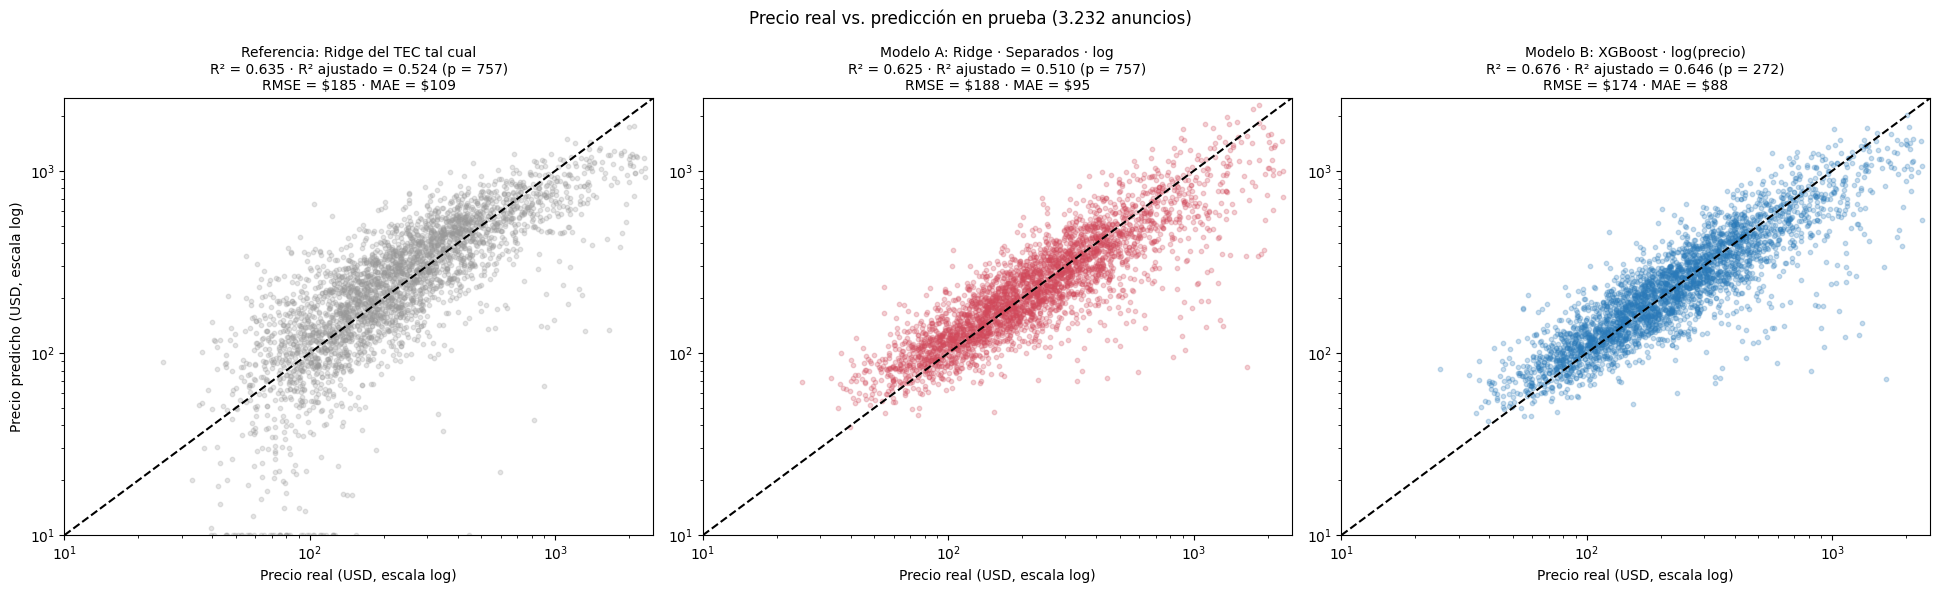

,Referencia: Ridge del TEC tal cual,Modelo A: Ridge · Separados · log,Modelo B: XGBoost · log(precio),anuncios
MAE (USD) por rango de precio,,,,
Up to $100,52.5,28.3,25.3,494
$100–250,68.0,42.3,40.6,1364
$250–500,109.0,88.8,86.4,889
Over $500,280.0,319.5,290.7,485


In [56]:
# Número de columnas de cada modelo (después del one-hot), para el R² ajustado.
# Modelos separados por grupo: suma de las columnas de los 3 modelos.
# XGBoost: columnas de entrada (solo referencia: un modelo de árboles no tiene un número fijo de parámetros).
cols_separados = sum(d['model'].named_steps['prepare'].transform(d['X_test'].head(1)).shape[1] for d in datasets.values())
P_COLUMNS = {'Referencia: Ridge del TEC tal cual': cols_separados}
P_COLUMNS[f'Modelo A: Ridge · {BEST_RIDGE}'] = (cols_separados if BEST_RIDGE.startswith('Separados')
                                               else to_dense(ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)],
                                                    remainder='passthrough').fit_transform(train_all[BASE_FEATURES + GROUP_FLAGS])).shape[1])
if HAS_XGB:
    P_COLUMNS['Modelo B: XGBoost · log(precio)'] = A_train.shape[1]

fig, axes = plt.subplots(1, len(final_models), figsize=(6.5 * len(final_models), 6))
colors = ['#999999', '#d1495b', '#2a7ab9']
y = test_all['price_num']
for ax, (model_name, pred), color in zip(axes, final_models.items(), colors):
    ax.scatter(y, np.clip(pred, 10, None), alpha=0.25, s=10, color=color)
    ax.plot([10, 2500], [10, 2500], '--', color='black')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
    r2 = r2_score(y, pred)
    r2_adj = adjusted_r2(r2, len(y), P_COLUMNS[model_name])
    rmse = np.sqrt(mean_squared_error(y, pred))
    mae = mean_absolute_error(y, pred)
    ax.set_title(f"{model_name}\nR² = {r2:.3f} · R² ajustado = {r2_adj:.3f} (p = {P_COLUMNS[model_name]})\n"
                 f"RMSE = \\${rmse:.0f} · MAE = \\${mae:.0f}", fontsize=10)
    ax.set_xlabel('Precio real (USD, escala log)')
axes[0].set_ylabel('Precio predicho (USD, escala log)')
fig.suptitle('Precio real vs. predicción en prueba (3.232 anuncios)')
plt.tight_layout()
plt.show()


# Error por rango de precio (mismos rangos del TEC)
price_range = pd.cut(test_all['price_num'], bins=[0, 100, 250, 500, np.inf],
                     labels=['Up to $100', '$100–250', '$250–500', 'Over $500'])
mae_by_range = pd.DataFrame({m: (p - test_all['price_num']).abs().groupby(price_range, observed=False).mean()
                             for m, p in final_models.items()})
mae_by_range['anuncios'] = price_range.value_counts().reindex(mae_by_range.index)
display(mae_by_range.round(1).rename_axis('MAE (USD) por rango de precio'))

**Cada modelo por separado.** La Referencia del TEC y el Modelo A son en realidad **3 modelos Ridge, uno por grupo de precio**: se muestran sus 3 modelos, cada uno con sus métricas (filas = grupo). El **Modelo B es un solo XGBoost** entrenado con todos los precios juntos: se muestra en **un solo panel** con todos los anuncios de prueba, coloreados por grupo.

En el R² ajustado, `p` es el número de columnas del modelo de **ese grupo** (Ridge) o del modelo único (XGBoost, solo como referencia).


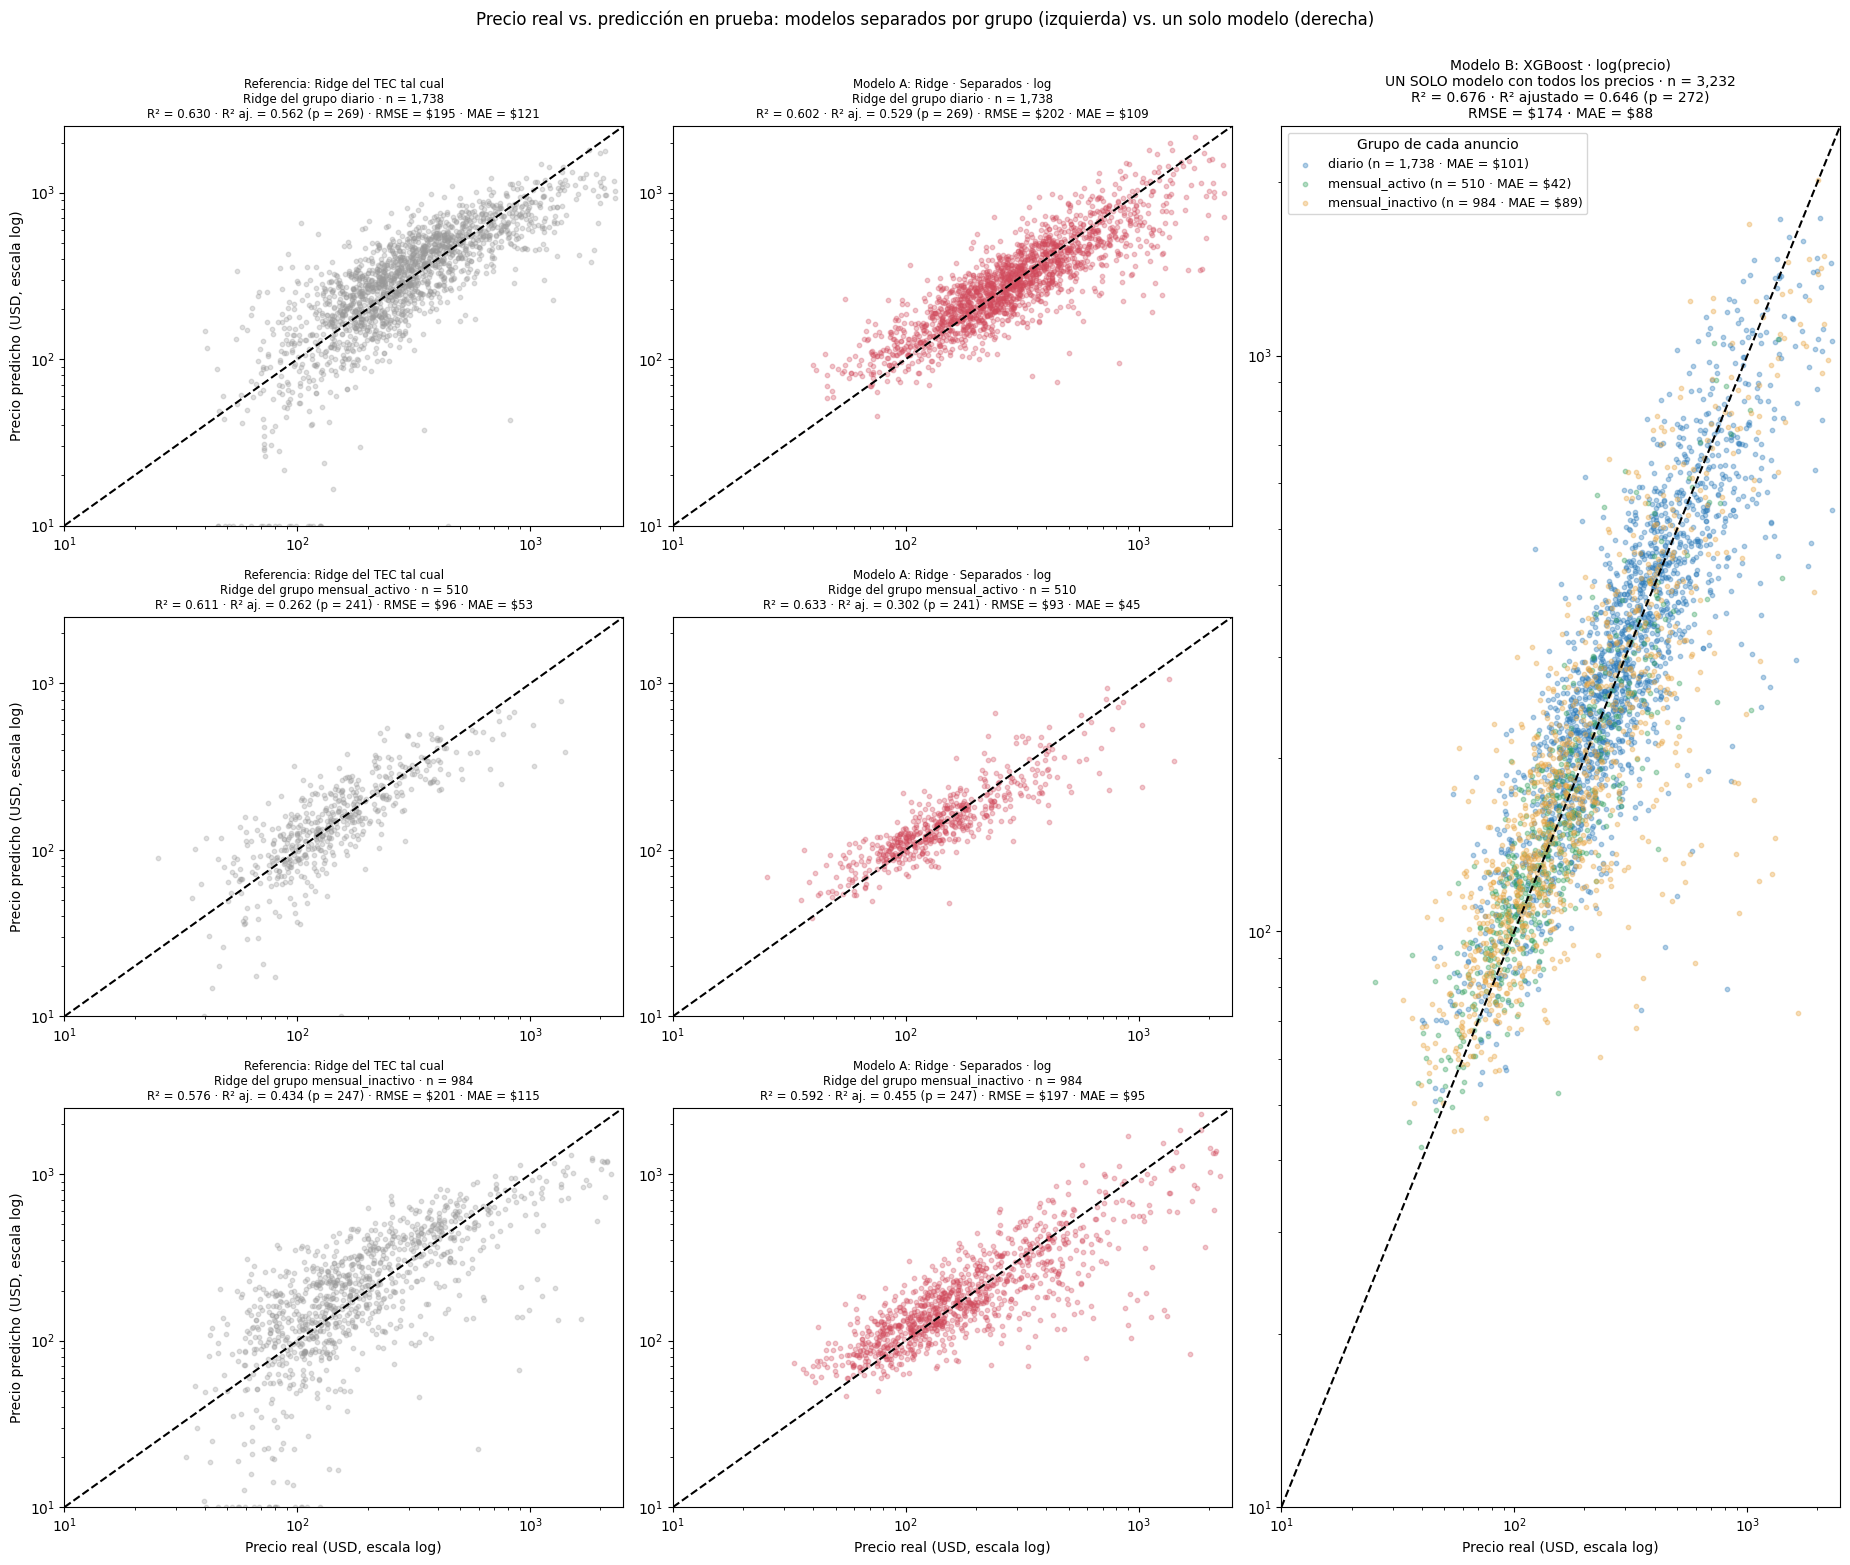

anuncios de prueba  \
modelo                             submodelo / evaluación                                                   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_diario                                  1738   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_diario                                  1738   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_activo                           510   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_activo                           510   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_inactivo                         984   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_inactivo                         984   
Modelo B: XGBoost · log(precio)    Un solo modelo · todos los anuncios                               3232   
                                   Mismo modelo · evaluado en df_modelo_diario                       1738   
                                   Mismo modelo · evaluado en df_modelo_mensual_ac...                 510   
                                   Mismo modelo · evaluado en df_modelo_mensual_in...                 984   

                                                                                       p (columnas)  \
modelo                             submodelo / evaluación                                             
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_diario                             269   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_diario                             269   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_activo                     241   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_activo                     241   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_inactivo                   247   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_inactivo                   247   
Modelo B: XGBoost · log(precio)    Un solo modelo · todos los anuncios                          272   
                                   Mismo modelo · evaluado en df_modelo_diario                  272   
                                   Mismo modelo · evaluado en df_modelo_mensual_ac...           272   
                                   Mismo modelo · evaluado en df_modelo_mensual_in...           272   

                                                                                          R²  \
modelo                             submodelo / evaluación                                      
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_diario                    0.630   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_diario                    0.602   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_activo            0.611   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_activo            0.633   
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_mensual_inactivo          0.576   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_mensual_inactivo          0.592   
Modelo B: XGBoost · log(precio)    Un solo modelo · todos los anuncios                 0.676   
                                   Mismo modelo · evaluado en df_modelo_diario         0.660   
                                   Mismo modelo · evaluado en df_modelo_mensual_ac...  0.674   
                                   Mismo modelo · evaluado en df_modelo_mensual_in...  0.642   

                                                                                       R² ajustado  \
modelo                             submodelo / evaluación                                            
Referencia: Ridge del TEC tal cual Ridge del grupo df_modelo_diario                          0.562   
Modelo A: Ridge · Separados · log  Ridge del grupo df_modelo_diario               

In [57]:
# Columnas del Ridge de cada grupo (mismas variables y datos para la Referencia y el Modelo A separado)
cols_by_group = {name: d['model'].named_steps['prepare'].transform(d['X_test'].head(1)).shape[1] for name, d in datasets.items()}
separated_models = {n: p for n, p in final_models.items() if not n.startswith('Modelo B')}
single_name = next((n for n in final_models if n.startswith('Modelo B')), None)

def metrics_with_p(y, p_hat, p_cols):
    r2 = r2_score(y, p_hat)
    return {'R²': r2, 'R² ajustado': adjusted_r2(r2, len(y), p_cols),
            'RMSE ($)': np.sqrt(mean_squared_error(y, p_hat)), 'MAE ($)': mean_absolute_error(y, p_hat)}

group_names = list(datasets)
group_colors = {'df_modelo_diario': '#2a7ab9', 'df_modelo_mensual_activo': '#2e9e5b', 'df_modelo_mensual_inactivo': '#e8a33d'}
n_sep = len(separated_models)
fig = plt.figure(figsize=(6.2 * (n_sep + 1), 5.2 * len(group_names)))
gs = fig.add_gridspec(len(group_names), n_sep + 1)
per_model_rows = []

# Modelos separados (3 Ridge cada uno): una fila por grupo
for i, group in enumerate(group_names):
    mask = test_all['dataset'] == group
    y = test_all.loc[mask, 'price_num']
    for j, (model_name, pred) in enumerate(separated_models.items()):
        p_cols = cols_by_group[group]
        m = metrics_with_p(y, pred[mask], p_cols)
        per_model_rows.append({'modelo': model_name, 'submodelo / evaluación': f'Ridge del grupo {group}',
                               'anuncios de prueba': len(y), 'p (columnas)': p_cols, **m})
        ax = fig.add_subplot(gs[i, j])
        ax.scatter(y, np.clip(pred[mask], 10, None), alpha=0.3, s=10, color=colors[j])
        ax.plot([10, 2500], [10, 2500], '--', color='black')
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
        ax.set_title(f"{model_name}\nRidge del grupo {group.replace('df_modelo_', '')} · n = {len(y):,}\n"
                     f"R² = {m['R²']:.3f} · R² aj. = {m['R² ajustado']:.3f} (p = {p_cols}) · "
                     f"RMSE = \\${m['RMSE ($)']:.0f} · MAE = \\${m['MAE ($)']:.0f}", fontsize=8.5)
        if i == len(group_names) - 1:
            ax.set_xlabel('Precio real (USD, escala log)')
        if j == 0:
            ax.set_ylabel('Precio predicho (USD, escala log)')

# Modelo B: un solo XGBoost con todos los anuncios, coloreados por grupo
if single_name is not None:
    ax = fig.add_subplot(gs[:, n_sep])
    y_all, pred_all = test_all['price_num'], final_models[single_name]
    p_cols = P_COLUMNS[single_name]
    m = metrics_with_p(y_all, pred_all, p_cols)
    per_model_rows.append({'modelo': single_name, 'submodelo / evaluación': 'Un solo modelo · todos los anuncios',
                           'anuncios de prueba': len(y_all), 'p (columnas)': p_cols, **m})
    for group in group_names:
        mask = test_all['dataset'] == group
        mg = metrics_with_p(y_all[mask], pred_all[mask], p_cols)
        per_model_rows.append({'modelo': single_name, 'submodelo / evaluación': f'Mismo modelo · evaluado en {group}',
                               'anuncios de prueba': int(mask.sum()), 'p (columnas)': p_cols, **mg})
        ax.scatter(y_all[mask], np.clip(pred_all[mask], 10, None), alpha=0.35, s=10, color=group_colors[group],
                   label=f"{group.replace('df_modelo_', '')} (n = {mask.sum():,} · MAE = \\${mg['MAE ($)']:.0f})")
    ax.plot([10, 2500], [10, 2500], '--', color='black')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
    ax.set_title(f"{single_name}\nUN SOLO modelo con todos los precios · n = {len(y_all):,}\n"
                 f"R² = {m['R²']:.3f} · R² ajustado = {m['R² ajustado']:.3f} (p = {p_cols})\n"
                 f"RMSE = \\${m['RMSE ($)']:.0f} · MAE = \\${m['MAE ($)']:.0f}", fontsize=10)
    ax.set_xlabel('Precio real (USD, escala log)')
    ax.legend(title='Grupo de cada anuncio', loc='upper left', fontsize=9)

fig.suptitle('Precio real vs. predicción en prueba: modelos separados por grupo (izquierda) vs. un solo modelo (derecha)', y=1.0)
plt.tight_layout()
plt.show()

per_model_metrics = pd.DataFrame(per_model_rows).set_index(['modelo', 'submodelo / evaluación'])
per_model_metrics.round(3)


### 7.5 · ¿Qué variables usa más XGBoost?
Importancia por **ganancia**: cuánto reduce el error, en promedio, cada vez que un árbol usa esa variable para dividir los datos. Indica qué variables usa más el modelo, no el efecto causal de cada una sobre el precio.

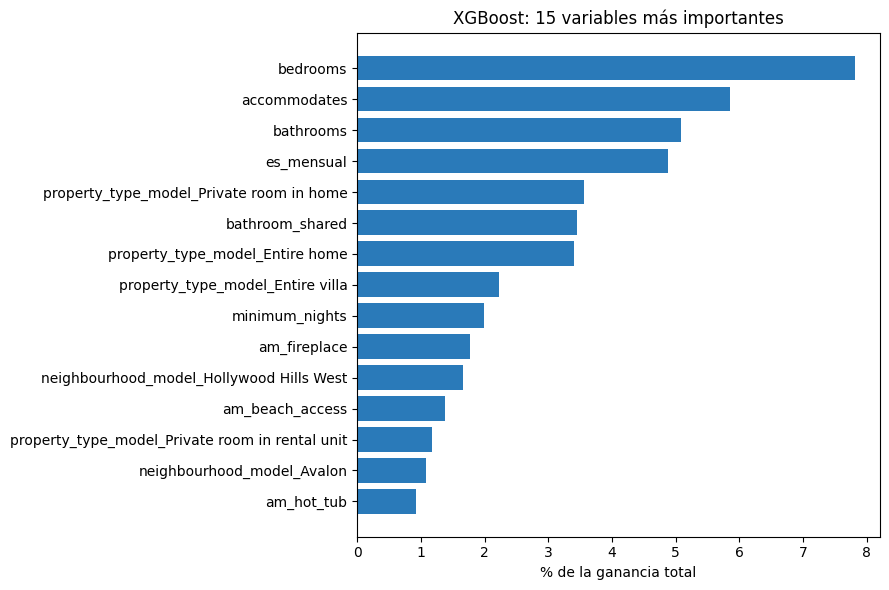

In [58]:
if HAS_XGB:
    gain = final_xgb.get_booster().get_score(importance_type='gain')
    importance = (pd.Series({feature_names[int(k[1:])]: v for k, v in gain.items()})
                  .sort_values(ascending=False))
    importance = importance / importance.sum() * 100
    top = importance.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top.index, top.values, color='#2a7ab9')
    ax.set_xlabel('% de la ganancia total')
    ax.set_title('XGBoost: 15 variables más importantes')
    plt.tight_layout()
    plt.show()

## 8 · Resultados finales: Modelo TEC vs. Modelo Andes
Los dos modelos finales de la sección 7, evaluados sobre los **mismos 3.232 anuncios de prueba** (`SEED = 42`):

| Nombre | Modelo | Configuración |
|---|---|---|
| **Modelo TEC** | Regresión lineal **Ridge** (el modelo del equipo del TEC, en su mejor versión) | Un modelo por grupo de precio · objetivo log(precio) · `alpha` por validación cruzada |
| **Modelo Andes** | **XGBoost** | Un solo modelo para los tres grupos con `es_mensual` y `activo` · objetivo log(precio) · regularización y número de árboles por validación cruzada y parada temprana |

In [59]:
FINAL = {'Modelo TEC': ridge_candidates[BEST_RIDGE]['pred']}
if HAS_XGB:
    FINAL['Modelo Andes'] = xgb_pred
FINAL_COLORS = {'Modelo TEC': '#d1495b', 'Modelo Andes': '#2a7ab9'}
y_true = test_all['price_num']

rows = []
for model_name, pred in FINAL.items():
    for scope in ['Todos'] + list(datasets):
        mask = slice(None) if scope == 'Todos' else (test_all['dataset'] == scope)
        rows.append({'evaluado en': scope, 'modelo': model_name, 'anuncios': int(np.size(y_true[mask])),
                     **final_metrics(y_true[mask], pred[mask])})
final_results = pd.DataFrame(rows).set_index(['evaluado en', 'modelo'])
final_results.round(3)

,,anuncios,R²,R² log,MAE ($),RMSE ($),error mediano ($),error % medio,negativas
evaluado en,modelo,,,,,,,,
Todos,Modelo TEC,3232,0.625,0.749,94.575,187.663,43.582,28.683,0
df_modelo_diario,Modelo TEC,1738,0.602,0.734,109.077,202.444,54.720,27.806,0
df_modelo_mensual_activo,Modelo TEC,510,0.633,0.753,44.938,93.349,23.066,23.169,0
df_modelo_mensual_inactivo,Modelo TEC,984,0.592,0.664,94.687,196.900,38.800,33.090,0
Todos,Modelo Andes,3232,0.676,0.769,88.400,174.342,40.715,27.016,0
df_modelo_diario,Modelo Andes,1738,0.660,0.763,101.445,186.992,52.316,25.931,0
df_modelo_mensual_activo,Modelo Andes,510,0.674,0.783,42.441,87.927,22.284,22.104,0
df_modelo_mensual_inactivo,Modelo Andes,984,0.642,0.677,89.180,184.575,38.217,31.478,0


### 8.1 · Precio real vs. predicción
Escala logarítmica en los dos ejes para que se vean bien los precios bajos y altos. Mientras más cerca de la diagonal, mejor.

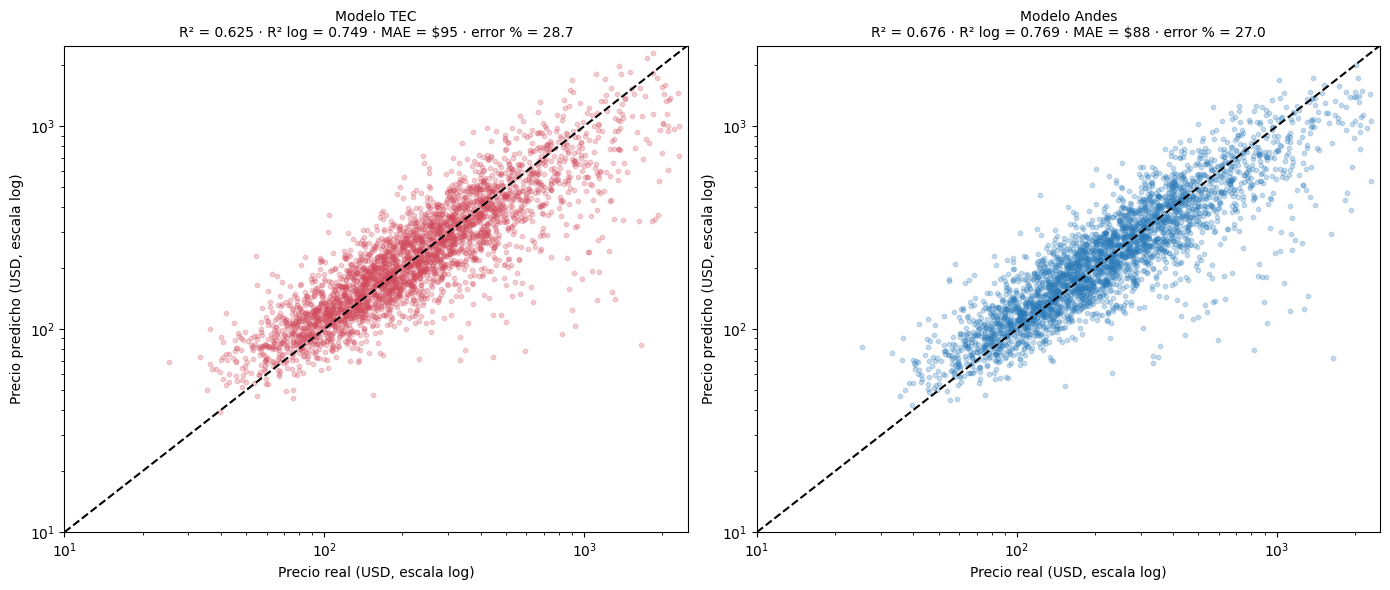

In [60]:
fig, axes = plt.subplots(1, len(FINAL), figsize=(7 * len(FINAL), 6))
axes = np.atleast_1d(axes)
for ax, (model_name, pred) in zip(axes, FINAL.items()):
    ax.scatter(y_true, np.clip(pred, 10, None), alpha=0.25, s=10, color=FINAL_COLORS[model_name])
    ax.plot([10, 2500], [10, 2500], '--', color='black')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
    m = final_metrics(y_true, pred)
    ax.set_title(f"{model_name}\nR² = {m['R²']:.3f} · R² log = {m['R² log']:.3f} · MAE = ${m['MAE ($)']:.0f} · error % = {m['error % medio']:.1f}",
                 fontsize=10)
    ax.set_xlabel('Precio real (USD, escala log)')
    ax.set_ylabel('Precio predicho (USD, escala log)')
plt.tight_layout()
plt.show()

### 8.2 · Distribución del error
Error porcentual de cada predicción: `(predicción − real) / real`. Un valor negativo significa que el modelo predijo menos que el precio publicado. Mientras más concentrado alrededor de 0, mejor.

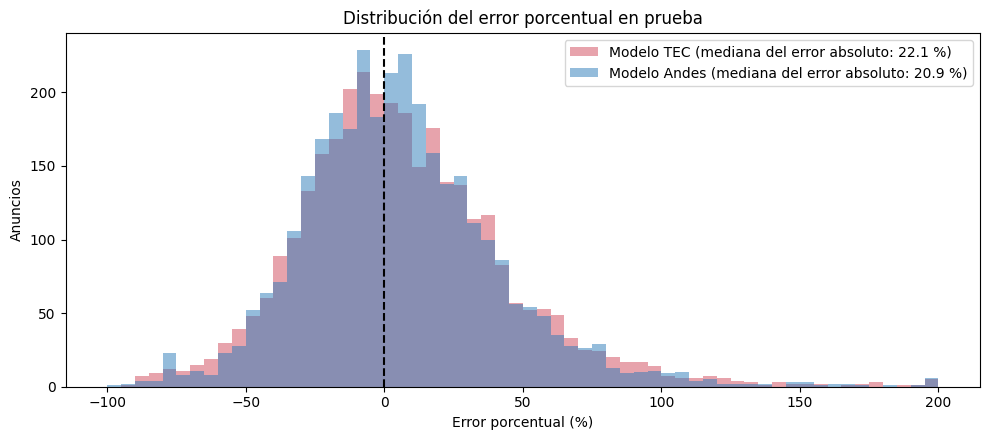

In [61]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(-100, 200, 61)
for model_name, pred in FINAL.items():
    pct_error = ((pred - y_true) / y_true * 100).clip(-100, 200)
    ax.hist(pct_error, bins=bins, alpha=0.5, color=FINAL_COLORS[model_name],
            label=f'{model_name} (mediana del error absoluto: {np.median(np.abs(pct_error)):.1f} %)')
ax.axvline(0, linestyle='--', color='black')
ax.set_xlabel('Error porcentual (%)')
ax.set_ylabel('Anuncios')
ax.set_title('Distribución del error porcentual en prueba')
ax.legend()
plt.tight_layout()
plt.show()

### 8.3 · Error por grupo y por rango de precio

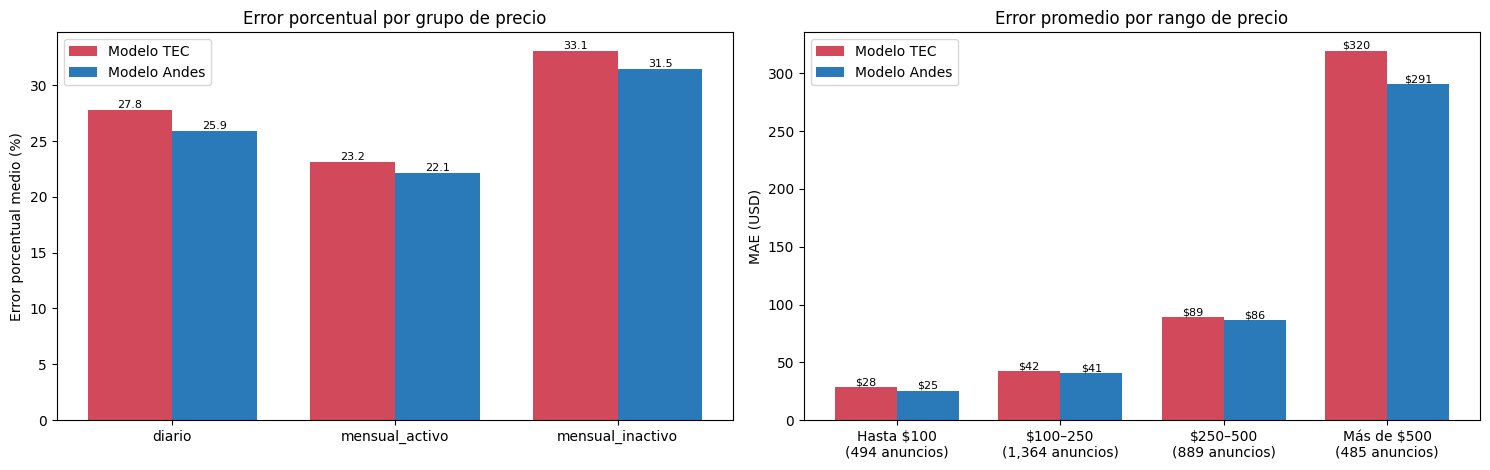

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
groups_order = list(datasets)
width = 0.38
x = np.arange(len(groups_order))
for k, model_name in enumerate(FINAL):
    vals = [final_results.loc[(g, model_name), 'error % medio'] for g in groups_order]
    bars = axes[0].bar(x + (k - 0.5) * width, vals, width, label=model_name, color=FINAL_COLORS[model_name])
    axes[0].bar_label(bars, fmt='%.1f', fontsize=8)
axes[0].set_xticks(x, [g.replace('df_modelo_', '') for g in groups_order])
axes[0].set_ylabel('Error porcentual medio (%)')
axes[0].set_title('Error porcentual por grupo de precio')
axes[0].legend()

price_range = pd.cut(y_true, bins=[0, 100, 250, 500, np.inf],
                     labels=['Hasta $100', '$100–250', '$250–500', 'Más de $500'])
mae_range = pd.DataFrame({m: (p - y_true).abs().groupby(price_range, observed=False).mean() for m, p in FINAL.items()})
x = np.arange(len(mae_range))
for k, model_name in enumerate(FINAL):
    bars = axes[1].bar(x + (k - 0.5) * width, mae_range[model_name], width, label=model_name, color=FINAL_COLORS[model_name])
    axes[1].bar_label(bars, fmt='$%.0f', fontsize=8)
counts = price_range.value_counts().reindex(mae_range.index)
axes[1].set_xticks(x, [f'{r}\n({n:,} anuncios)' for r, n in counts.items()])
axes[1].set_ylabel('MAE (USD)')
axes[1].set_title('Error promedio por rango de precio')
axes[1].legend()
plt.tight_layout()
plt.show()

### 8.4 · Resumen

In [63]:
summary_final = final_results.xs('Todos', level='evaluado en')[['R²', 'R² log', 'MAE ($)', 'error mediano ($)', 'error % medio', 'negativas']]
display(summary_final.round(3))
if HAS_XGB:
    tec, andes = summary_final.loc['Modelo TEC'], summary_final.loc['Modelo Andes']
    print(f"El Modelo Andes reduce el MAE de ${tec['MAE ($)']:.0f} a ${andes['MAE ($)']:.0f} "
          f"({(1 - andes['MAE ($)'] / tec['MAE ($)']) * 100:.1f} % menos) y el error porcentual medio de "
          f"{tec['error % medio']:.1f} % a {andes['error % medio']:.1f} %.")
    print(f"R² en dólares: {tec['R²']:.3f} (TEC) vs {andes['R²']:.3f} (Andes) | "
          f"R² en escala log: {tec['R² log']:.3f} (TEC) vs {andes['R² log']:.3f} (Andes)")

,R²,R² log,MAE ($),error mediano ($),error % medio,negativas
modelo,,,,,,
Modelo TEC,0.625,0.749,94.575,43.582,28.683,0
Modelo Andes,0.676,0.769,88.400,40.715,27.016,0


El Modelo Andes reduce el MAE de $95 a $88 (6.5 % menos) y el error porcentual medio de 28.7 % a 27.0 %.
R² en dólares: 0.625 (TEC) vs 0.676 (Andes) | R² en escala log: 0.749 (TEC) vs 0.769 (Andes)


## 9 · Modelo de clasificación (metodología del TEC)
Se repite **exactamente la clasificación del equipo del TEC** (secciones 6.1, 6.2 y 8.1–8.4 de su notebook), aplicada a **todos nuestros precios juntos** (los tres grupos: diario, mensual activo y mensual inactivo), con la misma división de la sección 7.1 (`SEED = 42`).

| Paso | Igual al TEC |
|---|---|
| Referencia de mercado | Mediana de precio de anuncios **de entrenamiento** con el mismo `neighbourhood_model`, `property_type_model`, `bedrooms` y `accommodates` |
| Si hay menos de 5 comparables | Mediana del vecindario; si no existe, mediana global de entrenamiento |
| Categorías | `price_ratio = precio / mediana`: **< 0,90** Opportunity to Charge More · **0,90–1,10** Competitive · **> 1,10** Too High |
| Clasificador | Árbol de decisión (`max_depth=2`) entrenado con `price_ratio` |
| Evaluación | Accuracy, precision, recall y F1 (ponderados) en prueba, y matriz de confusión |

### 9.1 · Referencia de mercado: mediana de anuncios comparables
Las medianas se calculan **solo con anuncios de entrenamiento**, para no usar los precios de prueba como referencia.

In [64]:
GROUP_COLS = ['neighbourhood_model', 'property_type_model', 'bedrooms', 'accommodates']
reference = train_all[GROUP_COLS + ['price_num', 'dataset']].copy()

market = reference.groupby(GROUP_COLS)['price_num'].agg(['median', 'count'])
neighborhood_medians = reference.groupby('neighbourhood_model')['price_num'].median()
overall_median = reference['price_num'].median()

def market_median_for(frame):
    joined = frame[GROUP_COLS].join(market, on=GROUP_COLS)
    fallback = frame['neighbourhood_model'].map(neighborhood_medians)
    has_comparables = joined['count'] >= 5
    return joined['median'].where(has_comparables, fallback).fillna(overall_median), has_comparables

classified = test_all[['price_num', 'dataset'] + GROUP_COLS].copy()
classified['market_median'], classified['has_5_comparables'] = market_median_for(classified)
print(f'Grupos de comparables en entrenamiento: {len(market):,}')
print(f"Anuncios de prueba con ≥ 5 comparables: {classified['has_5_comparables'].mean():.1%} "
      f"(el resto usa la mediana del vecindario o la global)")
classified[['price_num', 'market_median', 'has_5_comparables']].head()

Grupos de comparables en entrenamiento: 6,144
Anuncios de prueba con ≥ 5 comparables: 31.6% (el resto usa la mediana del vecindario o la global)


,price_num,market_median,has_5_comparables
df_modelo_diario_304,399.0,125.53,False
df_modelo_diario_6350,310.0,242.50,True
df_modelo_diario_8421,258.2,146.03,True
df_modelo_diario_1670,399.0,280.00,False
df_modelo_diario_6215,379.0,239.33,False


### 9.2 · Aplicar las tres categorías
Si el precio está entre 90 % y 110 % de la mediana comparable es **Competitive**. Fuera de ese intervalo se indica la dirección del ajuste sugerido.

,anuncios,%
pricing_alert,,
Opportunity to Charge More,1369,42.4
Competitive,408,12.6
Too High,1455,45.0


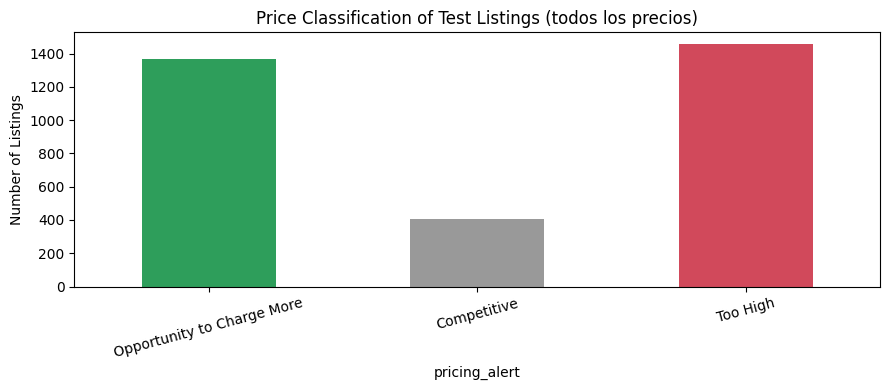

In [65]:
ALERT_CLASSES = ['Opportunity to Charge More', 'Competitive', 'Too High']

def pricing_alert(ratio):
    return np.select([ratio < 0.90, ratio > 1.10], ['Opportunity to Charge More', 'Too High'], default='Competitive')

classified['price_ratio'] = classified['price_num'] / classified['market_median']
classified['pricing_alert'] = pricing_alert(classified['price_ratio'])

alert_counts = classified['pricing_alert'].value_counts().reindex(ALERT_CLASSES)
display((alert_counts.to_frame('anuncios').assign(**{'%': (alert_counts / len(classified) * 100).round(1)})))

alert_counts.plot(kind='bar', figsize=(9, 4), color=['#2e9e5b', '#999999', '#d1495b'])
plt.title('Price Classification of Test Listings (todos los precios)')
plt.ylabel('Number of Listings')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Importante:** estas alertas son **comparaciones de precios anunciados**, no una garantía de ocupación, ingresos o precio óptimo.

### 9.3 · Etiquetas de entrenamiento a partir de precios comparables

In [66]:
train_median, _ = market_median_for(reference)
train_ratio = reference['price_num'] / train_median
train_labels = pricing_alert(train_ratio)
print(f'Training examples: {len(train_ratio):,}')

Training examples: 12,926


### 9.4 · Entrenar el clasificador

In [67]:
from sklearn.tree import DecisionTreeClassifier, export_text

classification_model = DecisionTreeClassifier(max_depth=2, random_state=SEED)
classification_model.fit(pd.DataFrame({'price_ratio': train_ratio}), train_labels)
print('Classifier trained successfully!')
print(export_text(classification_model, feature_names=['price_ratio'], decimals=3))

Classifier trained successfully!
|--- price_ratio <= 1.100
|   |--- price_ratio <= 0.900
|   |   |--- class: Opportunity to Charge More
|   |--- price_ratio >  0.900
|   |   |--- class: Competitive
|--- price_ratio >  1.100
|   |--- class: Too High



### 9.5 · Evaluar accuracy, precision, recall y F1-score en prueba

In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

class_test_X = classified[['price_ratio']]
class_test_y = classified['pricing_alert']
class_pred = classification_model.predict(class_test_X)

class_results = pd.DataFrame([{
    'Accuracy': accuracy_score(class_test_y, class_pred),
    'Precision': precision_score(class_test_y, class_pred, average='weighted'),
    'Recall': recall_score(class_test_y, class_pred, average='weighted'),
    'F1-score': f1_score(class_test_y, class_pred, average='weighted'),
}], index=['Nuestros datos (todos los precios)'])
class_results.loc['TEC original (su base)'] = [1.0, 1.0, 1.0, 1.0]
display(class_results.round(4))
print(f'Test records: {len(class_test_y):,}')

,Accuracy,Precision,Recall,F1-score
Nuestros datos (todos los precios),1.0,1.0,1.0,1.0
TEC original (su base),1.0,1.0,1.0,1.0


Test records: 3,232


### 9.6 · Matriz de confusión

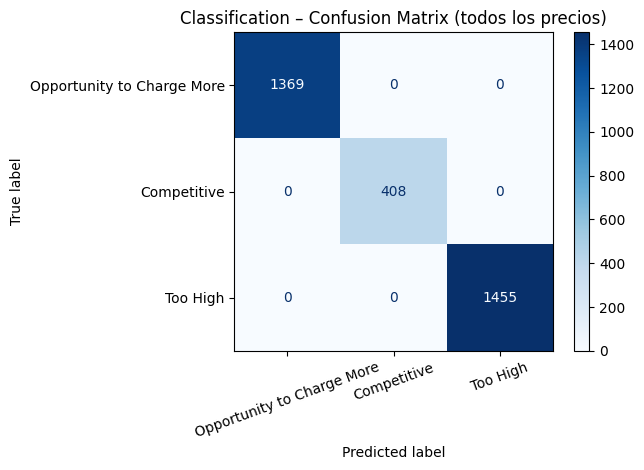

In [69]:
ConfusionMatrixDisplay.from_predictions(class_test_y, class_pred, labels=ALERT_CLASSES,
                                        cmap='Blues', xticks_rotation=20)
plt.title('Classification – Confusion Matrix (todos los precios)')
plt.tight_layout()
plt.show()

**Interpretación (igual que el TEC):** una accuracy cercana al 100 % significa que el árbol replica el umbral de ±10 %, porque aprende de etiquetas calculadas con esa misma regla. **No** demuestra que esos precios aumenten las reservas.

### 9.7 · ¿Cómo se reparten las alertas por grupo de precio?
Al usar **todos los precios juntos**, la mediana de comparables mezcla anuncios diarios y mensuales con las mismas características. Esta tabla muestra qué alerta recibe cada grupo.

In [70]:
by_group = pd.crosstab(classified['dataset'], classified['pricing_alert'], normalize='index').reindex(columns=ALERT_CLASSES) * 100
by_group['anuncios'] = classified['dataset'].value_counts()
by_group['% con ≥ 5 comparables'] = classified.groupby('dataset')['has_5_comparables'].mean() * 100
by_group['price_ratio mediano'] = classified.groupby('dataset')['price_ratio'].median()
by_group.round(2)

pricing_alert,Opportunity to Charge More,Competitive,Too High,anuncios,% con ≥ 5 comparables,price_ratio mediano
dataset,,,,,,
df_modelo_diario,27.96,13.41,58.63,1738,31.13,1.23
df_modelo_mensual_activo,69.22,11.76,19.02,510,33.73,0.70
df_modelo_mensual_inactivo,53.86,11.69,34.45,984,31.20,0.83
